In [3]:
# ==============================================================
# 纯净版消融实验：双实验设置 (Random Split vs. Temporal Transfer)
# 降级对比版：无监督/伪自适应 DNN 融合 (不接触真实特征与标签)
# 包含：均值标准差表格生成 + 配对样本 t 检验 (Paired t-test)
# 新增：自适应网络 w_logits (Lambda) 动态追踪与最终结果打印
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# --- Sklearn & Scipy ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from scipy import stats

# 统一的方法排序，保证表格列顺序一致
METHOD_ORDER = [
    "Single-Obj (Class)", 
    "Single-Obj (Year)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed Weights)", 
    "GA+DNN (Adaptive - Ours)"
]

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def normalize_mi(mi_scores):
    mi = np.array(mi_scores)
    return (mi - mi.min()) / (mi.max() - mi.min() + 1e-8)

# ==============================================================
# 1. Safe & Fast Fitness Functions (MI 查表化)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def Obj1_Max_Class_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    mi_scores = opts['mi_class']
    return -float(np.mean(mi_scores[sel])) + _size_penalty(len(sel), len(x))

def Obj2_Min_Redundancy_Safe(x, opts):
    sel = np.where(x == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1)) # 防崩溃
    np.fill_diagonal(C, 0)
    n = C.shape[0]
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt_in.shape[1])

def Obj3_Min_Year_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    mi_scores = opts['mi_year']
    return float(np.mean(mi_scores[sel])) + _size_penalty(len(sel), len(x))

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    P = np.random.rand()
    idx = np.searchsorted(C, P)
    return min(idx, len(prob) - 1)

def jfs(opts, fitness_function):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = opts['xt_in'].shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)
    
    fit = np.array([fitness_function(X[i, :], opts) for i in range(N)]).reshape(-1, 1)
    best_idx = int(np.argmin(fit)); fitG = fit[best_idx].item()
    
    for t in range(1, max_iter):
        fit_shifted = fit - np.min(fit)
        inv_fit = 1.0 / (1.0 + fit_shifted + 1e-8)
        prob = inv_fit / inv_fit.sum()
        
        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)
        
        for i in range(Nc):
            P1 = X[roulette_wheel(prob)]; P2 = X[roulette_wheel(prob)]
            idx = np.random.randint(1, dim - 1) if dim > 2 else 1
            
            child1 = np.concatenate((P1[:idx], P2[idx:])); child2 = np.concatenate((P2[:idx], P1[idx:]))
            child1 ^= (np.random.rand(dim) < MR).astype(int)
            child2 ^= (np.random.rand(dim) < MR).astype(int)
            x1[i], x2[i] = child1, child2
            
        Xnew = np.vstack((x1, x2))
        Fnew = np.array([fitness_function(Xnew[i, :], opts) for i in range(Xnew.shape[0])]).reshape(-1, 1)
        if np.min(Fnew) < fitG: fitG = np.min(Fnew)
        
        XX = np.vstack((X, Xnew)); FF = np.vstack((fit, Fnew))
        keep = np.argsort(FF.ravel())[:N]; X, fit = XX[keep], FF[keep]
        
    return {'X': X, 'fit': fit}

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# 3. Unsupervised SoftMaskNet
# ==============================================================
class SoftMaskDNN(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.fc1 = nn.Linear(3 * num_features, 64)
        self.fc2 = nn.Linear(64, num_features)
    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))

def train_softmask_dnn_adaptive_unsupervised(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    X_list = []
    if len(pop1)==0: pop1=np.zeros((1, num_features))
    if len(pop2)==0: pop2=np.zeros((1, num_features))
    if len(pop3)==0: pop3=np.zeros((1, num_features))

    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
        
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)
    model = SoftMaskDNN(num_features).to(device)
    w_logits = nn.Parameter(torch.ones(3, device=device))
    optimizer = torch.optim.Adam(list(model.parameters()) + [w_logits], lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    
    # 用于记录 lambda 的轨迹
    lambda_history = []
    
    model.train()
    for epoch in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            current_w = F.softmax(w_logits, dim=0)
            pred_logits = model(bx)
            target = (current_w[0]*m1 + current_w[1]*m2 + current_w[2]*m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            
        # 记录关键 Epoch 的 Lambda 变化 (第 1 轮及每 15 轮)
        if epoch == 0 or (epoch + 1) % 15 == 0:
            with torch.no_grad():
                curr_lambda = F.softmax(w_logits, dim=0).cpu().numpy()
                lambda_history.append(f"Ep{epoch+1}: [{curr_lambda[0]:.3f}, {curr_lambda[1]:.3f}, {curr_lambda[2]:.3f}]")
                
    # 打印最终确定的权重以及历史变化轨迹
    with torch.no_grad():
        final_lambda = F.softmax(w_logits, dim=0).cpu().numpy()
        print(f"      └─> [Lambda 演变记录] {' -> '.join(lambda_history)}")
        print(f"      └─> [最终确定 Lambda] Obj1(类相关): {final_lambda[0]:.4f} | Obj2(低冗余): {final_lambda[1]:.4f} | Obj3(域不变): {final_lambda[2]:.4f}")
        
    model.eval()
    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

def train_softmask_dnn_fixed_unsupervised(pop1, pop2, pop3, num_features, epochs=60, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    X_list = []
    if len(pop1)==0: pop1=np.zeros((1, num_features))
    if len(pop2)==0: pop2=np.zeros((1, num_features))
    if len(pop3)==0: pop3=np.zeros((1, num_features))

    for _ in range(800):
        i1, i2, i3 = random.randint(0, len(pop1)-1), random.randint(0, len(pop2)-1), random.randint(0, len(pop3)-1)
        inp = torch.tensor(np.concatenate([pop1[i1], pop2[i2], pop3[i3]]), dtype=torch.float32)
        X_list.append(inp)
        
    dataloader = DataLoader(TensorDataset(torch.stack(X_list)), batch_size=32, shuffle=True)
    model = SoftMaskDNN(num_features).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    fixed_w = [1/3, 1/3, 1/3]
    
    model.train()
    for _ in range(epochs):
        for (bx,) in dataloader:
            bx = bx.to(device)
            m1, m2, m3 = torch.chunk(bx, 3, dim=1)
            pred_logits = model(bx)
            target = (fixed_w[0]*m1 + fixed_w[1]*m2 + fixed_w[2]*m3).clamp(0.0, 1.0)
            loss = loss_fn(pred_logits, target)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            
    model.eval()
    with torch.no_grad():
        m1 = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device)
        m2 = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device)
        m3 = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device)
        inp = torch.cat([m1, m2, m3]).unsqueeze(0)
        scores = torch.sigmoid(model(inp)).squeeze(0).cpu().numpy()
    return scores

# ==============================================================
# 4. Core Evaluation Routine
# ==============================================================
def run_fs_and_evaluate(xtrain, xtest, ytrain, ytest, yyear_tr, run_idx, exp_name):
    n_features = xtrain.shape[1]
    
    print(f"  [{exp_name} - Run {run_idx}] Pre-computing Mutual Information...")
    mi_class = mutual_info_classif(xtrain, ytrain, random_state=42)
    mi_year = mutual_info_classif(xtrain, yyear_tr, random_state=42)
    
    opts = {'xt_in': xtrain, 'mi_class': mi_class, 'mi_year': mi_year, 'N': 40, 'T': 40}
    
    print(f"  [{exp_name} - Run {run_idx}] Evolving Independent GA Populations...")
    res1 = jfs(opts, Obj1_Max_Class_MI_Fast); pop1 = keep_elite(res1['X'], res1['fit'])
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe); pop2 = keep_elite(res2['X'], res2['fit'])
    res3 = jfs(opts, Obj3_Min_Year_MI_Fast); pop3 = keep_elite(res3['X'], res3['fit'])
    
    print(f"  [{exp_name} - Run {run_idx}] Computing Ablation Variants (UNSUPERVISED)...")
    scores_single_class = pop1.mean(0)
    scores_single_year = pop3.mean(0)
    scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
    
    # 无监督变体
    scores_dnn_fixed = train_softmask_dnn_fixed_unsupervised(pop1, pop2, pop3, n_features)
    scores_dnn_adapt = train_softmask_dnn_adaptive_unsupervised(pop1, pop2, pop3, n_features)
    
    def get_top_k(scores, k):
        idx = np.argsort(scores)[::-1][:k]
        return idx if len(idx) > 0 else [0]
        
    clf = LinearDiscriminantAnalysis()
    results = []
    
    for k in range(1, 16):
        methods = {
            "Single-Obj (Class)": get_top_k(scores_single_class, k),
            "Single-Obj (Year)": get_top_k(scores_single_year, k),
            "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
            "GA+DNN (Fixed Weights)": get_top_k(scores_dnn_fixed, k),
            "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k)
        }
        
        for m_name, idx in methods.items():
            clf.fit(xtrain[:, idx], ytrain)
            acc_disease = clf.score(xtest[:, idx], ytest)
            
            results.append({
                "Experiment": exp_name,
                "Run": run_idx, 
                "Method": m_name, 
                "K": k, 
                "Accuracy": acc_disease
            })
            
    return results

# ==============================================================
# 5. 统计检验工具函数 (配对样本 T 检验)
# ==============================================================
def get_significance_stars(p_val):
    if pd.isna(p_val): return ""
    if p_val < 0.001: return "***"
    if p_val < 0.01: return "**"
    if p_val < 0.05: return "*"
    return ""

def perform_paired_ttest(df, experiment_name, target_method="GA+DNN (Adaptive - Ours)"):
    """执行并格式化 T-test 结果，对比 Target 和其他所有的 Baseline"""
    df_exp = df[df["Experiment"] == experiment_name]
    baselines = [m for m in METHOD_ORDER if m != target_method]
    k_values = sorted(df_exp["K"].unique())
    
    ttest_results = []
    for k in k_values:
        df_k = df_exp[df_exp["K"] == k]
        target_accs = df_k[df_k["Method"] == target_method].sort_values("Run")["Accuracy"].values
        
        row_result = {"K": k}
        for baseline in baselines:
            base_accs = df_k[df_k["Method"] == baseline].sort_values("Run")["Accuracy"].values
            
            # 配对T检验
            if len(target_accs) > 1 and len(base_accs) > 1:
                t_stat, p_val = stats.ttest_rel(target_accs, base_accs)
                stars = get_significance_stars(p_val)
                row_result[baseline] = f"p={p_val:.4f}{stars}"
            else:
                row_result[baseline] = "N/A"
        
        ttest_results.append(row_result)
        
    df_ttest = pd.DataFrame(ttest_results).set_index("K")
    return df_ttest

# ==============================================================
# 6. Dual-Experiment Orchestrator
# ==============================================================
def run_dual_experiment_benchmark(features, class_labels, year_raw, target_year_val=4, n_runs=10):
    le_year = LabelEncoder()
    y_year_encoded = le_year.fit_transform(year_raw)
    
    if target_year_val in year_raw:
        target_year_idx = le_year.transform([target_year_val])[0]
    else:
        target_year_idx = np.max(y_year_encoded)
        print(f"Warning: target_year_val {target_year_val} not found, using encoded year {target_year_idx} for testing.")

    all_results = []
    print("="*70)
    print(f"Starting DUAL-EXPERIMENT Ablation (UNSUPERVISED CONTRAST): {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Starting Run {run_idx}/{n_runs}...")
        
        # Experiment 1
        xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, _ = train_test_split(
            features, class_labels, y_year_encoded, 
            test_size=0.3, stratify=class_labels, random_state=current_seed
        )
        res1 = run_fs_and_evaluate(xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, run_idx, "Exp1_Random_Split")
        all_results.extend(res1)
        
        # Experiment 2
        test_mask = (y_year_encoded == target_year_idx)
        train_mask = ~test_mask
        
        xt_tr2, xt_te2 = features[train_mask], features[test_mask]
        yt_tr2, yt_te2 = class_labels[train_mask], class_labels[test_mask]
        yr_tr2 = y_year_encoded[train_mask]
        
        res2 = run_fs_and_evaluate(xt_tr2, xt_te2, yt_tr2, yt_te2, yr_tr2, run_idx, "Exp2_Temporal_Transfer")
        all_results.extend(res2)

    df_results = pd.DataFrame(all_results)
    
    # -------------------------------------------------------------
    # Generate Pivot Tables (Mean ± Std)
    # -------------------------------------------------------------
    print("\n\n" + "="*60)
    print("            UNSUPERVISED ABLATION TABLES (Mean ± Std)")
    print("="*60)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"
    
    df_exp1 = df_results[df_results["Experiment"] == "Exp1_Random_Split"]
    table_exp1 = df_exp1.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp1 = table_exp1[[m for m in METHOD_ORDER if m in table_exp1.columns]]
    print("\n[TABLE 1] Experiment 1: Random 70/30 Split [UNSUPERVISED]")
    print(table_exp1)
    table_exp1.to_csv("Table_Exp1_RandomSplit_LDA_MeanStd_Unsupervised.csv")
    
    df_exp2 = df_results[df_results["Experiment"] == "Exp2_Temporal_Transfer"]
    table_exp2 = df_exp2.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp2 = table_exp2[[m for m in METHOD_ORDER if m in table_exp2.columns]]
    print("\n[TABLE 2] Experiment 2: Temporal Transfer (Train <= 23, Test 24) [UNSUPERVISED]")
    print(table_exp2)
    table_exp2.to_csv("Table_Exp2_TemporalTransfer_LDA_MeanStd_Unsupervised.csv")
    
    # -------------------------------------------------------------
    # Generate P-Value Tables (Paired T-Test)
    # -------------------------------------------------------------
    print("\n\n" + "="*60)
    print("         STATISTICAL SIGNIFICANCE (Paired T-Test vs Ours)")
    print("              * p<0.05, ** p<0.01, *** p<0.001")
    print("="*60)
    
    ttest_exp1 = perform_paired_ttest(df_results, "Exp1_Random_Split")
    print("\n[T-TEST] Experiment 1: Random Split (P-Values relative to 'Adaptive - Ours')")
    print(ttest_exp1)
    ttest_exp1.to_csv("Table_Exp1_RandomSplit_TTest_PValues.csv")
    
    ttest_exp2 = perform_paired_ttest(df_results, "Exp2_Temporal_Transfer")
    print("\n[T-TEST] Experiment 2: Temporal Transfer (P-Values relative to 'Adaptive - Ours')")
    print(ttest_exp2)
    ttest_exp2.to_csv("Table_Exp2_TemporalTransfer_TTest_PValues.csv")

    print("\n-> 带标准差的对照组文件和 T 检验 (p-value) 文件均已生成！")

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("Spectral_DataSet(1).xlsx")
        
        class_col_idx = -4
        year_col_idx = -1
        y_class_raw = df.iloc[:, class_col_idx].values
        mask_cls = np.isin(y_class_raw, [2, 3])
        df_filtered = df[mask_cls].copy()
        
        balanced_indices = []
        curr_years = df_filtered.iloc[:, year_col_idx].values
        curr_classes = df_filtered.iloc[:, class_col_idx].values
        unique_years = np.unique(curr_years)
        
        for yr in unique_years:
            for cls in [2, 3]:
                match_mask = (curr_years == yr) & (curr_classes == cls)
                match_indices = np.where(match_mask)[0]
                if len(match_indices) >= 100:
                    selected = np.random.choice(match_indices, 100, replace=False)
                else: 
                    selected = match_indices
                balanced_indices.extend(selected)
                
        df_balanced = df_filtered.iloc[balanced_indices].copy()
        df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
        
        X = df_balanced.iloc[:, :600].values.astype(float)
        X = normalize(X + 1e-8, norm='l1', axis=1)
        y_cls = np.where(df_balanced.iloc[:, class_col_idx].values == 2, 0, 1)
        y_year_raw = df_balanced.iloc[:, year_col_idx].values
        
        run_dual_experiment_benchmark(X, y_cls, y_year_raw, target_year_val=4, n_runs=30)
        
    except Exception as e:
        print(f"Error: {e}")
        print("Running safe mock benchmark...")
        X_mock = np.random.rand(500, 200)
        X_mock = normalize(X_mock + 1e-8, norm='l1', axis=1)
        y_cls_mock = np.random.randint(0, 2, 500)
        y_year_mock = np.random.choice([2020, 2021, 2022, 2023, 2024], 500)
        run_dual_experiment_benchmark(X_mock, y_cls_mock, y_year_mock, target_year_val=2024, n_runs=2)

Loading Data...
Starting DUAL-EXPERIMENT Ablation (UNSUPERVISED CONTRAST): 30 Runs

>>> Starting Run 1/30...
  [Exp1_Random_Split - Run 1] Pre-computing Mutual Information...
  [Exp1_Random_Split - Run 1] Evolving Independent GA Populations...
  [Exp1_Random_Split - Run 1] Computing Ablation Variants (UNSUPERVISED)...
      └─> [Lambda 演变记录] Ep1: [0.344, 0.329, 0.328] -> Ep15: [0.601, 0.205, 0.194] -> Ep30: [0.817, 0.096, 0.088] -> Ep45: [0.908, 0.048, 0.044] -> Ep60: [0.948, 0.027, 0.025]
      └─> [最终确定 Lambda] Obj1(类相关): 0.9479 | Obj2(低冗余): 0.0275 | Obj3(域不变): 0.0247
  [Exp2_Temporal_Transfer - Run 1] Pre-computing Mutual Information...
  [Exp2_Temporal_Transfer - Run 1] Evolving Independent GA Populations...
  [Exp2_Temporal_Transfer - Run 1] Computing Ablation Variants (UNSUPERVISED)...
      └─> [Lambda 演变记录] Ep1: [0.343, 0.329, 0.328] -> Ep15: [0.611, 0.189, 0.200] -> Ep30: [0.821, 0.088, 0.091] -> Ep45: [0.910, 0.045, 0.045] -> Ep60: [0.949, 0.026, 0.026]
      └─> [最终确定 Lambda

In [6]:
# ==============================================================
# 纯净版消融实验：双实验设置 (Random Split vs. Temporal Transfer)
# 升级版：弱监督代理任务 DNN 融合 (Task-Guided Feature Fusion)
# 包含：均值标准差表格生成 + 配对样本 t 检验 (Paired t-test)
# 新增：自适应网络 w_logits (Lambda) 动态追踪与最终结果打印
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# --- Sklearn & Scipy ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from scipy import stats

# 统一的方法排序，保证表格列顺序一致
METHOD_ORDER = [
    "Single-Obj (Class)", 
    "Single-Obj (Year)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed Weights)", 
    "GA+DNN (Adaptive - Ours)"
]

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ==============================================================
# 1. Safe & Fast Fitness Functions (MI 查表化)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def Obj1_Max_Class_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    mi_scores = opts['mi_class']
    return -float(np.mean(mi_scores[sel])) + _size_penalty(len(sel), len(x))

def Obj2_Min_Redundancy_Safe(x, opts):
    sel = np.where(x == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    n = C.shape[0]
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt_in.shape[1])

def Obj3_Min_Year_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    mi_scores = opts['mi_year']
    return float(np.mean(mi_scores[sel])) + _size_penalty(len(sel), len(x))

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    P = np.random.rand()
    idx = np.searchsorted(C, P)
    return min(idx, len(prob) - 1)

def jfs(opts, fitness_function):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = opts['xt_in'].shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)
    
    fit = np.array([fitness_function(X[i, :], opts) for i in range(N)]).reshape(-1, 1)
    best_idx = int(np.argmin(fit)); fitG = fit[best_idx].item()
    
    for t in range(1, max_iter):
        fit_shifted = fit - np.min(fit)
        inv_fit = 1.0 / (1.0 + fit_shifted + 1e-8)
        prob = inv_fit / inv_fit.sum()
        
        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)
        
        for i in range(Nc):
            P1 = X[roulette_wheel(prob)]; P2 = X[roulette_wheel(prob)]
            idx = np.random.randint(1, dim - 1) if dim > 2 else 1
            
            child1 = np.concatenate((P1[:idx], P2[idx:])); child2 = np.concatenate((P2[:idx], P1[idx:]))
            child1 ^= (np.random.rand(dim) < MR).astype(int)
            child2 ^= (np.random.rand(dim) < MR).astype(int)
            x1[i], x2[i] = child1, child2
            
        Xnew = np.vstack((x1, x2))
        Fnew = np.array([fitness_function(Xnew[i, :], opts) for i in range(Xnew.shape[0])]).reshape(-1, 1)
        if np.min(Fnew) < fitG: fitG = np.min(Fnew)
        
        XX = np.vstack((X, Xnew)); FF = np.vstack((fit, Fnew))
        keep = np.argsort(FF.ravel())[:N]; X, fit = XX[keep], FF[keep]
        
    return {'X': X, 'fit': fit}

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# ==============================================================
# 3. WEAKLY SUPERVISED SoftMaskNet (强制权重依赖版)
# ==============================================================
class SoftMaskProxyNet(nn.Module):
    def __init__(self, num_features, adaptive=True):
        super().__init__()
        self.adaptive = adaptive
        
        # 自适应权重 (Lambda)
        if self.adaptive:
            # 初始化时稍微打破平衡，防止梯度鞍点
            self.w_logits = nn.Parameter(torch.tensor([1.1, 1.0, 0.9]))
        else:
            self.register_buffer('fixed_w', torch.tensor([1/3, 1/3, 1/3]))
            
        # ⚠️ 删除了 refine 层，强迫网络不能作弊修改 Mask！
        
        # 代理分类器：直接接收过滤后的特征进行预测
        self.cls_head = nn.Sequential(
            nn.Linear(num_features, 64),
            nn.ReLU(),
            nn.Dropout(0.2), # 加入轻微 Dropout 防止过拟合
            nn.Linear(64, 1)
        )

    def get_mask(self, m1, m2, m3):
        # 计算特征融合
        w = F.softmax(self.w_logits, dim=0) if self.adaptive else self.fixed_w
        # 因为 m1, m2, m3 是 0或1的二进制掩码，且 w 之和为1
        # 所以 base_mask 天然在 [0, 1] 之间，不需要再用 sigmoid
        fused_mask = w[0]*m1 + w[1]*m2 + w[2]*m3
        return fused_mask, w

    def forward(self, m1, m2, m3, x_raw):
        fused_mask, w = self.get_mask(m1, m2, m3)
        # 用融合后的 Mask 过滤原始特征
        masked_x = x_raw * fused_mask
        # 代理分类器进行疾病预测
        cls_logits = self.cls_head(masked_x)
        return cls_logits, w


def train_softmask_dnn_proxy(pop1, pop2, pop3, xtrain, ytrain, num_features, adaptive=True, epochs=80, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
    x_tensor = torch.tensor(xtrain, dtype=torch.float32)
    y_tensor = torch.tensor(ytrain, dtype=torch.float32).unsqueeze(1)
    dataloader = DataLoader(TensorDataset(x_tensor, y_tensor), batch_size=32, shuffle=True)
    
    model = SoftMaskProxyNet(num_features, adaptive=adaptive).to(device)
    
    # ⚠️ 双速优化器：给 Lambda 极大的学习率，强迫它去寻找最优权重！
    if adaptive:
        optimizer = torch.optim.Adam([
            {'params': model.cls_head.parameters(), 'lr': lr},
            {'params': [model.w_logits], 'lr': 0.05}  # 50倍学习率！
        ])
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        
    loss_fn = nn.BCEWithLogitsLoss()
    
    lambda_history = []
    
    model.train()
    for epoch in range(epochs):
        for bx, by in dataloader:
            bx, by = bx.to(device), by.to(device)
            
            # 动态采样
            idx1 = np.random.randint(0, len(pop1), bx.shape[0])
            idx2 = np.random.randint(0, len(pop2), bx.shape[0])
            idx3 = np.random.randint(0, len(pop3), bx.shape[0])
            
            m1_batch = torch.tensor(pop1[idx1], dtype=torch.float32).to(device)
            m2_batch = torch.tensor(pop2[idx2], dtype=torch.float32).to(device)
            m3_batch = torch.tensor(pop3[idx3], dtype=torch.float32).to(device)
            
            cls_logits, current_w = model(m1_batch, m2_batch, m3_batch, bx)
            loss = loss_fn(cls_logits, by)
            
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            
        if adaptive and (epoch == 0 or (epoch + 1) % 20 == 0):
            with torch.no_grad():
                current_lambda = F.softmax(model.w_logits, dim=0).cpu().numpy()
                lambda_history.append(f"Ep{epoch+1}: [{current_lambda[0]:.3f}, {current_lambda[1]:.3f}, {current_lambda[2]:.3f}]")
                
    if adaptive:
        with torch.no_grad():
            final_lambda = F.softmax(model.w_logits, dim=0).cpu().numpy()
            print(f"      └─> [Lambda 演变记录] {' -> '.join(lambda_history)}")
            print(f"      └─> [最终确定 Lambda] Obj1(分类): {final_lambda[0]:.4f} | Obj2(冗余): {final_lambda[1]:.4f} | Obj3(年份): {final_lambda[2]:.4f}")
            
    # 推理阶段
    model.eval()
    with torch.no_grad():
        m1_mean = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        m2_mean = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        m3_mean = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        final_mask, _ = model.get_mask(m1_mean, m2_mean, m3_mean)
        
    return final_mask.squeeze(0).cpu().numpy()

# ==============================================================
# 4. Core Evaluation Routine
# ==============================================================
def run_fs_and_evaluate(xtrain, xtest, ytrain, ytest, yyear_tr, run_idx, exp_name):
    n_features = xtrain.shape[1]
    
    print(f"  [{exp_name} - Run {run_idx}] Pre-computing Mutual Information...")
    mi_class = mutual_info_classif(xtrain, ytrain, random_state=42)
    mi_year = mutual_info_classif(xtrain, yyear_tr, random_state=42)
    
    opts = {'xt_in': xtrain, 'mi_class': mi_class, 'mi_year': mi_year, 'N': 40, 'T': 40}
    
    print(f"  [{exp_name} - Run {run_idx}] Evolving Independent GA Populations...")
    res1 = jfs(opts, Obj1_Max_Class_MI_Fast); pop1 = keep_elite(res1['X'], res1['fit'])
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe); pop2 = keep_elite(res2['X'], res2['fit'])
    res3 = jfs(opts, Obj3_Min_Year_MI_Fast); pop3 = keep_elite(res3['X'], res3['fit'])
    
    print(f"  [{exp_name} - Run {run_idx}] Computing Variants (WEAKLY SUPERVISED PROXY)...")
    scores_single_class = pop1.mean(0)
    scores_single_year = pop3.mean(0)
    scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
    
    # 代理任务变体 (传入了 xtrain 和 ytrain 引导网络)
    scores_dnn_fixed = train_softmask_dnn_proxy(pop1, pop2, pop3, xtrain, ytrain, n_features, adaptive=False)
    scores_dnn_adapt = train_softmask_dnn_proxy(pop1, pop2, pop3, xtrain, ytrain, n_features, adaptive=True)
    
    def get_top_k(scores, k):
        idx = np.argsort(scores)[::-1][:k]
        return idx if len(idx) > 0 else [0]
        
    clf = LinearDiscriminantAnalysis()
    results = []
    
    for k in range(1, 16):
        methods = {
            "Single-Obj (Class)": get_top_k(scores_single_class, k),
            "Single-Obj (Year)": get_top_k(scores_single_year, k),
            "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
            "GA+DNN (Fixed Weights)": get_top_k(scores_dnn_fixed, k),
            "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k)
        }
        
        for m_name, idx in methods.items():
            clf.fit(xtrain[:, idx], ytrain)
            acc_disease = clf.score(xtest[:, idx], ytest)
            
            results.append({
                "Experiment": exp_name,
                "Run": run_idx, 
                "Method": m_name, 
                "K": k, 
                "Accuracy": acc_disease
            })
            
    return results

# ==============================================================
# 5. 统计检验工具函数 (配对样本 T 检验)
# ==============================================================
def get_significance_stars(p_val):
    if pd.isna(p_val): return ""
    if p_val < 0.001: return "***"
    if p_val < 0.01: return "**"
    if p_val < 0.05: return "*"
    return ""

def perform_paired_ttest(df, experiment_name, target_method="GA+DNN (Adaptive - Ours)"):
    df_exp = df[df["Experiment"] == experiment_name]
    baselines = [m for m in METHOD_ORDER if m != target_method]
    k_values = sorted(df_exp["K"].unique())
    
    ttest_results = []
    for k in k_values:
        df_k = df_exp[df_exp["K"] == k]
        target_accs = df_k[df_k["Method"] == target_method].sort_values("Run")["Accuracy"].values
        
        row_result = {"K": k}
        for baseline in baselines:
            base_accs = df_k[df_k["Method"] == baseline].sort_values("Run")["Accuracy"].values
            
            if len(target_accs) > 1 and len(base_accs) > 1:
                t_stat, p_val = stats.ttest_rel(target_accs, base_accs)
                stars = get_significance_stars(p_val)
                row_result[baseline] = f"p={p_val:.4f}{stars}"
            else:
                row_result[baseline] = "N/A"
        
        ttest_results.append(row_result)
        
    df_ttest = pd.DataFrame(ttest_results).set_index("K")
    return df_ttest

# ==============================================================
# 6. Dual-Experiment Orchestrator
# ==============================================================
def run_dual_experiment_benchmark(features, class_labels, year_raw, target_year_val=4, n_runs=10):
    le_year = LabelEncoder()
    y_year_encoded = le_year.fit_transform(year_raw)
    
    if target_year_val in year_raw:
        target_year_idx = le_year.transform([target_year_val])[0]
    else:
        target_year_idx = np.max(y_year_encoded)
        print(f"Warning: target_year_val {target_year_val} not found, using encoded year {target_year_idx} for testing.")

    all_results = []
    print("="*70)
    print(f"Starting DUAL-EXPERIMENT Ablation (PROXY SUPERVISED): {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Starting Run {run_idx}/{n_runs}...")
        
        xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, _ = train_test_split(
            features, class_labels, y_year_encoded, 
            test_size=0.3, stratify=class_labels, random_state=current_seed
        )
        res1 = run_fs_and_evaluate(xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, run_idx, "Exp1_Random_Split")
        all_results.extend(res1)
        
        test_mask = (y_year_encoded == target_year_idx)
        train_mask = ~test_mask
        
        xt_tr2, xt_te2 = features[train_mask], features[test_mask]
        yt_tr2, yt_te2 = class_labels[train_mask], class_labels[test_mask]
        yr_tr2 = y_year_encoded[train_mask]
        
        res2 = run_fs_and_evaluate(xt_tr2, xt_te2, yt_tr2, yt_te2, yr_tr2, run_idx, "Exp2_Temporal_Transfer")
        all_results.extend(res2)

    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("            PROXY SUPERVISED TABLES (Mean ± Std)")
    print("="*60)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"
    
    df_exp1 = df_results[df_results["Experiment"] == "Exp1_Random_Split"]
    table_exp1 = df_exp1.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp1 = table_exp1[[m for m in METHOD_ORDER if m in table_exp1.columns]]
    print("\n[TABLE 1] Experiment 1: Random 70/30 Split [PROXY]")
    print(table_exp1)
    table_exp1.to_csv("Table_Exp1_RandomSplit_LDA_MeanStd_Proxy.csv")
    
    df_exp2 = df_results[df_results["Experiment"] == "Exp2_Temporal_Transfer"]
    table_exp2 = df_exp2.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp2 = table_exp2[[m for m in METHOD_ORDER if m in table_exp2.columns]]
    print("\n[TABLE 2] Experiment 2: Temporal Transfer [PROXY]")
    print(table_exp2)
    table_exp2.to_csv("Table_Exp2_TemporalTransfer_LDA_MeanStd_Proxy.csv")
    
    print("\n\n" + "="*60)
    print("         STATISTICAL SIGNIFICANCE (Paired T-Test vs Ours)")
    print("="*60)
    
    ttest_exp1 = perform_paired_ttest(df_results, "Exp1_Random_Split")
    print("\n[T-TEST] Experiment 1: Random Split")
    print(ttest_exp1)
    
    ttest_exp2 = perform_paired_ttest(df_results, "Exp2_Temporal_Transfer")
    print("\n[T-TEST] Experiment 2: Temporal Transfer")
    print(ttest_exp2)

    print("\n-> 带标准差的对照组文件和 T 检验 (p-value) 文件均已生成！")

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("Spectral_DataSet(1).xlsx")
        
        class_col_idx = -4
        year_col_idx = -1
        y_class_raw = df.iloc[:, class_col_idx].values
        mask_cls = np.isin(y_class_raw, [2, 3])
        df_filtered = df[mask_cls].copy()
        
        balanced_indices = []
        curr_years = df_filtered.iloc[:, year_col_idx].values
        curr_classes = df_filtered.iloc[:, class_col_idx].values
        unique_years = np.unique(curr_years)
        
        for yr in unique_years:
            for cls in [2, 3]:
                match_mask = (curr_years == yr) & (curr_classes == cls)
                match_indices = np.where(match_mask)[0]
                if len(match_indices) >= 100:
                    selected = np.random.choice(match_indices, 100, replace=False)
                else: 
                    selected = match_indices
                balanced_indices.extend(selected)
                
        df_balanced = df_filtered.iloc[balanced_indices].copy()
        df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
        
        X = df_balanced.iloc[:, :600].values.astype(float)
        X = normalize(X + 1e-8, norm='l1', axis=1)
        y_cls = np.where(df_balanced.iloc[:, class_col_idx].values == 2, 0, 1)
        y_year_raw = df_balanced.iloc[:, year_col_idx].values
        
        run_dual_experiment_benchmark(X, y_cls, y_year_raw, target_year_val=4, n_runs=30)
        
    except Exception as e:
        print(f"Error: {e}")
        print("Running safe mock benchmark...")
        X_mock = np.random.rand(500, 200)
        X_mock = normalize(X_mock + 1e-8, norm='l1', axis=1)
        y_cls_mock = np.random.randint(0, 2, 500)
        y_year_mock = np.random.choice([2020, 2021, 2022, 2023, 2024], 500)
        run_dual_experiment_benchmark(X_mock, y_cls_mock, y_year_mock, target_year_val=2024, n_runs=2)

Loading Data...
Starting DUAL-EXPERIMENT Ablation (PROXY SUPERVISED): 30 Runs

>>> Starting Run 1/30...
  [Exp1_Random_Split - Run 1] Pre-computing Mutual Information...
  [Exp1_Random_Split - Run 1] Evolving Independent GA Populations...
  [Exp1_Random_Split - Run 1] Computing Variants (WEAKLY SUPERVISED PROXY)...
      └─> [Lambda 演变记录] Ep1: [0.397, 0.268, 0.334] -> Ep20: [0.000, 0.000, 1.000] -> Ep40: [0.000, 0.000, 1.000] -> Ep60: [0.000, 0.000, 1.000] -> Ep80: [0.000, 0.000, 1.000]
      └─> [最终确定 Lambda] Obj1(分类): 0.0000 | Obj2(冗余): 0.0000 | Obj3(年份): 1.0000
  [Exp2_Temporal_Transfer - Run 1] Pre-computing Mutual Information...
  [Exp2_Temporal_Transfer - Run 1] Evolving Independent GA Populations...
  [Exp2_Temporal_Transfer - Run 1] Computing Variants (WEAKLY SUPERVISED PROXY)...
      └─> [Lambda 演变记录] Ep1: [0.296, 0.228, 0.476] -> Ep20: [0.000, 0.000, 1.000] -> Ep40: [0.000, 0.000, 1.000] -> Ep60: [0.000, 0.000, 1.000] -> Ep80: [0.000, 0.000, 1.000]
      └─> [最终确定 Lambda] Ob

In [9]:
# ==============================================================
# 纯净版消融实验：双实验设置 (Random Split vs. Temporal Transfer)
# 升级版：弱监督代理任务 DNN 融合 (Task-Guided Feature Fusion)
# 包含：均值标准差表格生成 + 配对样本 t 检验 (Paired t-test)
# 新增：多组 Fixed 权重对照组 + 最终自适应 Lambda 的均值/方差统计
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# --- Sklearn & Scipy ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from scipy import stats

# 统一的方法排序，保证表格列顺序一致
METHOD_ORDER = [
    "Single-Obj (Class)", 
    "Single-Obj (Year)", 
    "Mean-Agg (No NN)", 
    "GA+DNN (Fixed W: Equal)",       # [0.33, 0.33, 0.33]
    "GA+DNN (Fixed W: 0.5,0.2,0.3)", # 偏重 Obj1
    "GA+DNN (Fixed W: 0.2,0.5,0.3)", # 偏重 Obj2
    "GA+DNN (Adaptive - Ours)"
]

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ==============================================================
# 1. Safe & Fast Fitness Functions (MI 查表化)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def Obj1_Max_Class_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    mi_scores = opts['mi_class']
    return -float(np.mean(mi_scores[sel])) + _size_penalty(len(sel), len(x))

def Obj2_Min_Redundancy_Safe(x, opts):
    sel = np.where(x == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    n = C.shape[0]
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt_in.shape[1])

def Obj3_Min_Year_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    mi_scores = opts['mi_year']
    return float(np.mean(mi_scores[sel])) + _size_penalty(len(sel), len(x))

# ==============================================================
# 2. GA Components
# ==============================================================
def init_position(lb, ub, N, dim):
    return lb + (ub - lb) * np.random.rand(N, dim)

def binary_conversion(X, thres):
    return (X > thres).astype(int)

def roulette_wheel(prob):
    C = np.cumsum(prob); C[-1] = 1.0
    P = np.random.rand()
    idx = np.searchsorted(C, P)
    return min(idx, len(prob) - 1)

def jfs(opts, fitness_function):
    ub, lb, thres = 1, 0, 0.5
    CR, MR, N, max_iter = 0.8, 0.01, opts['N'], opts['T']
    dim = opts['xt_in'].shape[1]
    X = binary_conversion(init_position(lb, ub, N, dim), thres)
    
    fit = np.array([fitness_function(X[i, :], opts) for i in range(N)]).reshape(-1, 1)
    best_idx = int(np.argmin(fit)); fitG = fit[best_idx].item()
    
    for t in range(1, max_iter):
        fit_shifted = fit - np.min(fit)
        inv_fit = 1.0 / (1.0 + fit_shifted + 1e-8)
        prob = inv_fit / inv_fit.sum()
        
        Nc = max(1, int(np.sum(np.random.rand(N) < CR)))
        x1, x2 = np.zeros((Nc, dim), dtype=int), np.zeros((Nc, dim), dtype=int)
        
        for i in range(Nc):
            P1 = X[roulette_wheel(prob)]; P2 = X[roulette_wheel(prob)]
            idx = np.random.randint(1, dim - 1) if dim > 2 else 1
            
            child1 = np.concatenate((P1[:idx], P2[idx:])); child2 = np.concatenate((P2[:idx], P1[idx:]))
            child1 ^= (np.random.rand(dim) < MR).astype(int)
            child2 ^= (np.random.rand(dim) < MR).astype(int)
            x1[i], x2[i] = child1, child2
            
        Xnew = np.vstack((x1, x2))
        Fnew = np.array([fitness_function(Xnew[i, :], opts) for i in range(Xnew.shape[0])]).reshape(-1, 1)
        if np.min(Fnew) < fitG: fitG = np.min(Fnew)
        
        XX = np.vstack((X, Xnew)); FF = np.vstack((fit, Fnew))
        keep = np.argsort(FF.ravel())[:N]; X, fit = XX[keep], FF[keep]
        
    return {'X': X, 'fit': fit}

def keep_elite(X, fit, elite_ratio=0.2):
    n = X.shape[0]; ne = max(5, int(np.ceil(n * elite_ratio)))
    idx = np.argsort(fit.ravel())[:ne]
    return X[idx]

# ==============================================================
# 3. WEAKLY SUPERVISED SoftMaskNet (强制权重依赖版)
# ==============================================================
class SoftMaskProxyNet(nn.Module):
    def __init__(self, num_features, adaptive=True, fixed_weights=None):
        super().__init__()
        self.adaptive = adaptive
        
        # 自适应权重 (Lambda) 或者 固定权重
        if self.adaptive:
            # 初始化时稍微打破平衡，防止梯度鞍点
            self.w_logits = nn.Parameter(torch.tensor([1.1, 1.0, 0.9]))
        else:
            if fixed_weights is None:
                fixed_weights = [1/3, 1/3, 1/3]
            self.register_buffer('fixed_w', torch.tensor(fixed_weights, dtype=torch.float32))
            
        # ⚠️ 删除了 refine 层，强迫网络不能作弊修改 Mask！
        # 代理分类器：直接接收过滤后的特征进行预测
        self.cls_head = nn.Sequential(
            nn.Linear(num_features, 64),
            nn.ReLU(),
            nn.Dropout(0.2), # 加入轻微 Dropout 防止过拟合
            nn.Linear(64, 1)
        )

    def get_mask(self, m1, m2, m3):
        # 计算特征融合
        w = F.softmax(self.w_logits, dim=0) if self.adaptive else self.fixed_w
        # 因为 m1, m2, m3 是 0或1的二进制掩码，且 w 之和为1
        # 所以 base_mask 天然在 [0, 1] 之间，不需要再用 sigmoid
        fused_mask = w[0]*m1 + w[1]*m2 + w[2]*m3
        return fused_mask, w

    def forward(self, m1, m2, m3, x_raw):
        fused_mask, w = self.get_mask(m1, m2, m3)
        # 用融合后的 Mask 过滤原始特征
        masked_x = x_raw * fused_mask
        # 代理分类器进行疾病预测
        cls_logits = self.cls_head(masked_x)
        return cls_logits, w


def train_softmask_dnn_proxy(pop1, pop2, pop3, xtrain, ytrain, num_features, adaptive=True, fixed_weights=None, epochs=80, lr=1e-3):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
    x_tensor = torch.tensor(xtrain, dtype=torch.float32)
    y_tensor = torch.tensor(ytrain, dtype=torch.float32).unsqueeze(1)
    dataloader = DataLoader(TensorDataset(x_tensor, y_tensor), batch_size=32, shuffle=True)
    
    model = SoftMaskProxyNet(num_features, adaptive=adaptive, fixed_weights=fixed_weights).to(device)
    
    # ⚠️ 双速优化器：给 Lambda 极大的学习率，强迫它去寻找最优权重！
    if adaptive:
        optimizer = torch.optim.Adam([
            {'params': model.cls_head.parameters(), 'lr': lr},
            {'params': [model.w_logits], 'lr': 0.01}  # 50倍学习率！
        ])
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        
    loss_fn = nn.BCEWithLogitsLoss()
    lambda_history = []
    
    model.train()
    for epoch in range(epochs):
        for bx, by in dataloader:
            bx, by = bx.to(device), by.to(device)
            
            # 动态采样
            idx1 = np.random.randint(0, len(pop1), bx.shape[0])
            idx2 = np.random.randint(0, len(pop2), bx.shape[0])
            idx3 = np.random.randint(0, len(pop3), bx.shape[0])
            
            m1_batch = torch.tensor(pop1[idx1], dtype=torch.float32).to(device)
            m2_batch = torch.tensor(pop2[idx2], dtype=torch.float32).to(device)
            m3_batch = torch.tensor(pop3[idx3], dtype=torch.float32).to(device)
            
            cls_logits, current_w = model(m1_batch, m2_batch, m3_batch, bx)
            loss = loss_fn(cls_logits, by)
            
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            
        if adaptive and (epoch == 0 or (epoch + 1) % 20 == 0):
            with torch.no_grad():
                current_lambda = F.softmax(model.w_logits, dim=0).cpu().numpy()
                lambda_history.append(f"Ep{epoch+1}: [{current_lambda[0]:.3f}, {current_lambda[1]:.3f}, {current_lambda[2]:.3f}]")
                
    final_lambda_val = None
    if adaptive:
        with torch.no_grad():
            final_lambda = F.softmax(model.w_logits, dim=0).cpu().numpy()
            final_lambda_val = final_lambda # 保存到外部统计
            print(f"      └─> [Lambda 演变记录] {' -> '.join(lambda_history)}")
            print(f"      └─> [最终确定 Lambda] Obj1(分类): {final_lambda[0]:.4f} | Obj2(冗余): {final_lambda[1]:.4f} | Obj3(年份): {final_lambda[2]:.4f}")
            
    # 推理阶段
    model.eval()
    with torch.no_grad():
        m1_mean = torch.tensor(pop1.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        m2_mean = torch.tensor(pop2.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        m3_mean = torch.tensor(pop3.mean(0), dtype=torch.float32).to(device).unsqueeze(0)
        final_mask, _ = model.get_mask(m1_mean, m2_mean, m3_mean)
        
    return final_mask.squeeze(0).cpu().numpy(), final_lambda_val

# ==============================================================
# 4. Core Evaluation Routine
# ==============================================================
def run_fs_and_evaluate(xtrain, xtest, ytrain, ytest, yyear_tr, run_idx, exp_name):
    n_features = xtrain.shape[1]
    
    print(f"  [{exp_name} - Run {run_idx}] Pre-computing Mutual Information...")
    mi_class = mutual_info_classif(xtrain, ytrain, random_state=42)
    mi_year = mutual_info_classif(xtrain, yyear_tr, random_state=42)
    
    opts = {'xt_in': xtrain, 'mi_class': mi_class, 'mi_year': mi_year, 'N': 40, 'T': 40}
    
    print(f"  [{exp_name} - Run {run_idx}] Evolving Independent GA Populations...")
    res1 = jfs(opts, Obj1_Max_Class_MI_Fast); pop1 = keep_elite(res1['X'], res1['fit'])
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe); pop2 = keep_elite(res2['X'], res2['fit'])
    res3 = jfs(opts, Obj3_Min_Year_MI_Fast); pop3 = keep_elite(res3['X'], res3['fit'])
    
    print(f"  [{exp_name} - Run {run_idx}] Computing Variants (WEAKLY SUPERVISED PROXY)...")
    scores_single_class = pop1.mean(0)
    scores_single_year = pop3.mean(0)
    scores_mean_agg = (pop1.mean(0) + pop2.mean(0) + pop3.mean(0)) / 3.0
    
    # 代理任务变体 - 各种权重组合
    scores_dnn_fixed_eq, _ = train_softmask_dnn_proxy(pop1, pop2, pop3, xtrain, ytrain, n_features, adaptive=False, fixed_weights=[1/3, 1/3, 1/3])
    scores_dnn_fixed_p1, _ = train_softmask_dnn_proxy(pop1, pop2, pop3, xtrain, ytrain, n_features, adaptive=False, fixed_weights=[0.5, 0.2, 0.3])
    scores_dnn_fixed_p2, _ = train_softmask_dnn_proxy(pop1, pop2, pop3, xtrain, ytrain, n_features, adaptive=False, fixed_weights=[0.2, 0.5, 0.3])
    scores_dnn_adapt, learned_lambda = train_softmask_dnn_proxy(pop1, pop2, pop3, xtrain, ytrain, n_features, adaptive=True)
    
    def get_top_k(scores, k):
        idx = np.argsort(scores)[::-1][:k]
        return idx if len(idx) > 0 else [0]
        
    clf = LinearDiscriminantAnalysis()
    results = []
    
    for k in range(1, 16):
        methods = {
            "Single-Obj (Class)": get_top_k(scores_single_class, k),
            "Single-Obj (Year)": get_top_k(scores_single_year, k),
            "Mean-Agg (No NN)": get_top_k(scores_mean_agg, k),
            "GA+DNN (Fixed W: Equal)": get_top_k(scores_dnn_fixed_eq, k),
            "GA+DNN (Fixed W: 0.5,0.2,0.3)": get_top_k(scores_dnn_fixed_p1, k),
            "GA+DNN (Fixed W: 0.2,0.5,0.3)": get_top_k(scores_dnn_fixed_p2, k),
            "GA+DNN (Adaptive - Ours)": get_top_k(scores_dnn_adapt, k)
        }
        
        for m_name, idx in methods.items():
            clf.fit(xtrain[:, idx], ytrain)
            acc_disease = clf.score(xtest[:, idx], ytest)
            
            results.append({
                "Experiment": exp_name,
                "Run": run_idx, 
                "Method": m_name, 
                "K": k, 
                "Accuracy": acc_disease
            })
            
    return results, learned_lambda

# ==============================================================
# 5. 统计检验工具函数 (配稳样本 T 检验)
# ==============================================================
def get_significance_stars(p_val):
    if pd.isna(p_val): return ""
    if p_val < 0.001: return "***"
    if p_val < 0.01: return "**"
    if p_val < 0.05: return "*"
    return ""

def perform_paired_ttest(df, experiment_name, target_method="GA+DNN (Adaptive - Ours)"):
    df_exp = df[df["Experiment"] == experiment_name]
    baselines = [m for m in METHOD_ORDER if m != target_method]
    k_values = sorted(df_exp["K"].unique())
    
    ttest_results = []
    for k in k_values:
        df_k = df_exp[df_exp["K"] == k]
        target_accs = df_k[df_k["Method"] == target_method].sort_values("Run")["Accuracy"].values
        
        row_result = {"K": k}
        for baseline in baselines:
            base_accs = df_k[df_k["Method"] == baseline].sort_values("Run")["Accuracy"].values
            
            if len(target_accs) > 1 and len(base_accs) > 1:
                t_stat, p_val = stats.ttest_rel(target_accs, base_accs)
                stars = get_significance_stars(p_val)
                row_result[baseline] = f"p={p_val:.4f}{stars}"
            else:
                row_result[baseline] = "N/A"
        
        ttest_results.append(row_result)
        
    df_ttest = pd.DataFrame(ttest_results).set_index("K")
    return df_ttest

# ==============================================================
# 6. Dual-Experiment Orchestrator
# ==============================================================
def run_dual_experiment_benchmark(features, class_labels, year_raw, target_year_val=4, n_runs=10):
    le_year = LabelEncoder()
    y_year_encoded = le_year.fit_transform(year_raw)
    
    if target_year_val in year_raw:
        target_year_idx = le_year.transform([target_year_val])[0]
    else:
        target_year_idx = np.max(y_year_encoded)
        print(f"Warning: target_year_val {target_year_val} not found, using encoded year {target_year_idx} for testing.")

    all_results = []
    lambdas_exp1 = []
    lambdas_exp2 = []
    
    print("="*70)
    print(f"Starting DUAL-EXPERIMENT Ablation (PROXY SUPERVISED): {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Starting Run {run_idx}/{n_runs}...")
        
        xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, _ = train_test_split(
            features, class_labels, y_year_encoded, 
            test_size=0.3, stratify=class_labels, random_state=current_seed
        )
        res1, lam1 = run_fs_and_evaluate(xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, run_idx, "Exp1_Random_Split")
        all_results.extend(res1)
        if lam1 is not None: lambdas_exp1.append(lam1)
        
        test_mask = (y_year_encoded == target_year_idx)
        train_mask = ~test_mask
        
        xt_tr2, xt_te2 = features[train_mask], features[test_mask]
        yt_tr2, yt_te2 = class_labels[train_mask], class_labels[test_mask]
        yr_tr2 = y_year_encoded[train_mask]
        
        res2, lam2 = run_fs_and_evaluate(xt_tr2, xt_te2, yt_tr2, yt_te2, yr_tr2, run_idx, "Exp2_Temporal_Transfer")
        all_results.extend(res2)
        if lam2 is not None: lambdas_exp2.append(lam2)

    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("            PROXY SUPERVISED TABLES (Mean ± Std)")
    print("="*60)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"
    
    df_exp1 = df_results[df_results["Experiment"] == "Exp1_Random_Split"]
    table_exp1 = df_exp1.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp1 = table_exp1[[m for m in METHOD_ORDER if m in table_exp1.columns]]
    print("\n[TABLE 1] Experiment 1: Random 70/30 Split [PROXY]")
    print(table_exp1)
    table_exp1.to_csv("Table_Exp1_RandomSplit_LDA_MeanStd_Proxy.csv")
    
    df_exp2 = df_results[df_results["Experiment"] == "Exp2_Temporal_Transfer"]
    table_exp2 = df_exp2.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp2 = table_exp2[[m for m in METHOD_ORDER if m in table_exp2.columns]]
    print("\n[TABLE 2] Experiment 2: Temporal Transfer [PROXY]")
    print(table_exp2)
    table_exp2.to_csv("Table_Exp2_TemporalTransfer_LDA_MeanStd_Proxy.csv")
    
    print("\n\n" + "="*60)
    print("         STATISTICAL SIGNIFICANCE (Paired T-Test vs Ours)")
    print("="*60)
    
    ttest_exp1 = perform_paired_ttest(df_results, "Exp1_Random_Split")
    print("\n[T-TEST] Experiment 1: Random Split")
    print(ttest_exp1)
    
    ttest_exp2 = perform_paired_ttest(df_results, "Exp2_Temporal_Transfer")
    print("\n[T-TEST] Experiment 2: Temporal Transfer")
    print(ttest_exp2)

    print("\n\n" + "="*60)
    print("         ADAPTIVE LAMBDA STATISTICS (Mean ± Std over runs)")
    print("="*60)
    if lambdas_exp1:
        l1_mean, l1_std = np.mean(lambdas_exp1, axis=0), np.std(lambdas_exp1, axis=0, ddof=1)
        print("\n[Exp1 Random Split] Final Learned Lambda Statistics:")
        print(f"  Obj1 (Class MI) : {l1_mean[0]:.4f} ± {l1_std[0]:.4f}")
        print(f"  Obj2 (Min Redun): {l1_mean[1]:.4f} ± {l1_std[1]:.4f}")
        print(f"  Obj3 (Year MI)  : {l1_mean[2]:.4f} ± {l1_std[2]:.4f}")
        
    if lambdas_exp2:
        l2_mean, l2_std = np.mean(lambdas_exp2, axis=0), np.std(lambdas_exp2, axis=0, ddof=1)
        print("\n[Exp2 Temporal Transfer] Final Learned Lambda Statistics:")
        print(f"  Obj1 (Class MI) : {l2_mean[0]:.4f} ± {l2_std[0]:.4f}")
        print(f"  Obj2 (Min Redun): {l2_mean[1]:.4f} ± {l2_std[1]:.4f}")
        print(f"  Obj3 (Year MI)  : {l2_mean[2]:.4f} ± {l2_std[2]:.4f}")

    print("\n-> 带标准差的对照组文件、T 检验 (p-value) 文件及 Lambda 统计均已完成并生成！")

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("Spectral_DataSet(1).xlsx")
        
        class_col_idx = -4
        year_col_idx = -1
        y_class_raw = df.iloc[:, class_col_idx].values
        mask_cls = np.isin(y_class_raw, [2, 3])
        df_filtered = df[mask_cls].copy()
        
        balanced_indices = []
        curr_years = df_filtered.iloc[:, year_col_idx].values
        curr_classes = df_filtered.iloc[:, class_col_idx].values
        unique_years = np.unique(curr_years)
        
        for yr in unique_years:
            for cls in [2, 3]:
                match_mask = (curr_years == yr) & (curr_classes == cls)
                match_indices = np.where(match_mask)[0]
                if len(match_indices) >= 100:
                    selected = np.random.choice(match_indices, 100, replace=False)
                else: 
                    selected = match_indices
                balanced_indices.extend(selected)
                
        df_balanced = df_filtered.iloc[balanced_indices].copy()
        df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
        
        X = df_balanced.iloc[:, :600].values.astype(float)
        X = normalize(X + 1e-8, norm='l1', axis=1)
        y_cls = np.where(df_balanced.iloc[:, class_col_idx].values == 2, 0, 1)
        y_year_raw = df_balanced.iloc[:, year_col_idx].values
        
        run_dual_experiment_benchmark(X, y_cls, y_year_raw, target_year_val=4, n_runs=30)
        
    except Exception as e:
        print(f"Error: {e}")
        print("Running safe mock benchmark...")
        X_mock = np.random.rand(500, 200)
        X_mock = normalize(X_mock + 1e-8, norm='l1', axis=1)
        y_cls_mock = np.random.randint(0, 2, 500)
        y_year_mock = np.random.choice([2020, 2021, 2022, 2023, 2024], 500)
        run_dual_experiment_benchmark(X_mock, y_cls_mock, y_year_mock, target_year_val=2024, n_runs=2)

Loading Data...
Starting DUAL-EXPERIMENT Ablation (PROXY SUPERVISED): 30 Runs

>>> Starting Run 1/30...
  [Exp1_Random_Split - Run 1] Pre-computing Mutual Information...
  [Exp1_Random_Split - Run 1] Evolving Independent GA Populations...
  [Exp1_Random_Split - Run 1] Computing Variants (WEAKLY SUPERVISED PROXY)...
      └─> [Lambda 演变记录] Ep1: [0.391, 0.313, 0.297] -> Ep20: [0.996, 0.001, 0.003] -> Ep40: [1.000, 0.000, 0.000] -> Ep60: [1.000, 0.000, 0.000] -> Ep80: [1.000, 0.000, 0.000]
      └─> [最终确定 Lambda] Obj1(分类): 0.9999 | Obj2(冗余): 0.0000 | Obj3(年份): 0.0000
  [Exp2_Temporal_Transfer - Run 1] Pre-computing Mutual Information...
  [Exp2_Temporal_Transfer - Run 1] Evolving Independent GA Populations...
  [Exp2_Temporal_Transfer - Run 1] Computing Variants (WEAKLY SUPERVISED PROXY)...
      └─> [Lambda 演变记录] Ep1: [0.416, 0.307, 0.278] -> Ep20: [0.998, 0.001, 0.001] -> Ep40: [1.000, 0.000, 0.000] -> Ep60: [1.000, 0.000, 0.000] -> Ep80: [1.000, 0.000, 0.000]
      └─> [最终确定 Lambda] Ob

In [10]:
# ==============================================================
# 纯净版消融实验：双实验设置 (Random Split vs. Temporal Transfer)
# 基准测试版：SOTA MOEAs (NSGA-II, NSGA-III, RVEA, SPEA2, MOEA/D)
# 依赖库要求：pip install pymoo==0.6.0
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
from scipy import stats

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Pymoo (v0.6.0+) ---
from pymoo.core.problem import Problem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.moo.nsga3 import NSGA3
from pymoo.algorithms.moo.spea2 import SPEA2
from pymoo.algorithms.moo.rvea import RVEA
from pymoo.algorithms.moo.moead import MOEAD
from pymoo.operators.crossover.pntx import SinglePointCrossover
from pymoo.operators.mutation.bitflip import BitflipMutation
from pymoo.operators.sampling.rnd import BinaryRandomSampling
from pymoo.util.ref_dirs import get_reference_directions
from pymoo.optimize import minimize

# 统一的方法排序
METHOD_ORDER = ["MOEA/D", "NSGA-II", "NSGA-III", "RVEA", "SPEA2"]

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

# ==============================================================
# 1. Safe & Fast Fitness Functions
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def Obj1_Max_Class_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return -float(np.mean(opts['mi_class'][sel])) + _size_penalty(len(sel), len(x))

def Obj2_Min_Redundancy_Safe(x, opts):
    sel = np.where(x == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    n = C.shape[0]
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt_in.shape[1])

def Obj3_Min_Year_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return float(np.mean(opts['mi_year'][sel])) + _size_penalty(len(sel), len(x))

# ==============================================================
# 2. Pymoo Problem Definition
# ==============================================================
class FeatureSelectionProblem(Problem):
    def __init__(self, opts, **kwargs):
        # 3 个目标，无等式/不等式约束，变量类型为布尔型 (0/1)
        super().__init__(n_var=opts['xt_in'].shape[1], 
                         n_obj=3, 
                         n_ieq_constr=0, 
                         xl=0, xu=1, vtype=bool, **kwargs)
        self.opts = opts

    def _evaluate(self, X, out, *args, **kwargs):
        # X is boolean array of shape (Pop_Size, n_var)
        f1 = np.zeros(X.shape[0])
        f2 = np.zeros(X.shape[0])
        f3 = np.zeros(X.shape[0])
        
        for i in range(X.shape[0]):
            mask = X[i].astype(int)
            f1[i] = Obj1_Max_Class_MI_Fast(mask, self.opts)
            f2[i] = Obj2_Min_Redundancy_Safe(mask, self.opts)
            f3[i] = Obj3_Min_Year_MI_Fast(mask, self.opts)
            
        out["F"] = np.column_stack([f1, f2, f3])

# ==============================================================
# 3. Core Evaluation Routine (SOTA MOEAs)
# ==============================================================
def run_moeas_and_evaluate(xtrain, xtest, ytrain, ytest, yyear_tr, run_idx, exp_name):
    n_features = xtrain.shape[1]
    
    print(f"  [{exp_name} - Run {run_idx}] Pre-computing Mutual Information...")
    mi_class = mutual_info_classif(xtrain, ytrain, random_state=42)
    mi_year = mutual_info_classif(xtrain, yyear_tr, random_state=42)
    opts = {'xt_in': xtrain, 'mi_class': mi_class, 'mi_year': mi_year}
    
    # 实例化问题
    problem = FeatureSelectionProblem(opts)
    
    # 根据论文设定：Das-Dennis 12 partitions 对 3 目标生成 91 个参考向量
    ref_dirs = get_reference_directions("das-dennis", 3, n_partitions=12)
    pop_size = len(ref_dirs) # 91
    
    # 统一算子
    sampling = BinaryRandomSampling()
    crossover = SinglePointCrossover(prob=0.8)
    mutation = BitflipMutation(prob=0.01)
    
    # 实例化算法
    algorithms = {
        "NSGA-II": NSGA2(pop_size=pop_size, sampling=sampling, crossover=crossover, mutation=mutation),
        "NSGA-III": NSGA3(ref_dirs=ref_dirs, pop_size=pop_size, sampling=sampling, crossover=crossover, mutation=mutation),
        "SPEA2": SPEA2(pop_size=pop_size, sampling=sampling, crossover=crossover, mutation=mutation),
        "RVEA": RVEA(ref_dirs=ref_dirs, pop_size=pop_size, sampling=sampling, crossover=crossover, mutation=mutation),
        "MOEA/D": MOEAD(ref_dirs=ref_dirs, n_neighbors=15, sampling=sampling, crossover=crossover, mutation=mutation)
    }
    
    def get_top_k(scores, k):
        idx = np.argsort(scores)[::-1][:k]
        return idx if len(idx) > 0 else np.array([0])
        
    clf = LinearDiscriminantAnalysis()
    results = []
    
    # 逐一运行所有 MOEAs
    for algo_name, algo in algorithms.items():
        print(f"    -> Optimizing with {algo_name}...")
        # 运行 40 代，与 GA-NN 保持一致
        res = minimize(problem, algo, ('n_gen', 40), seed=42+run_idx, verbose=False)
        
        # 提取 Pareto 前沿/最终种群的特征选择频率，用作 Soft Ranking
        # X: (Pop_Size, n_var) boolean
        final_pop = res.pop.get("X").astype(int)
        scores_algo = final_pop.mean(axis=0)
        
        for k in range(1, 16):
            idx = get_top_k(scores_algo, k)
            clf.fit(xtrain[:, idx], ytrain)
            acc = clf.score(xtest[:, idx], ytest)
            
            results.append({
                "Experiment": exp_name,
                "Run": run_idx, 
                "Method": algo_name, 
                "K": k, 
                "Accuracy": acc
            })
            
    return results

# ==============================================================
# 4. Dual-Experiment Orchestrator
# ==============================================================
def run_sota_benchmark(features, class_labels, year_raw, target_year_val=4, n_runs=10):
    le_year = LabelEncoder()
    y_year_encoded = le_year.fit_transform(year_raw)
    
    if target_year_val in year_raw:
        target_year_idx = le_year.transform([target_year_val])[0]
    else:
        target_year_idx = np.max(y_year_encoded)
        print(f"Warning: target_year_val {target_year_val} not found, using encoded year {target_year_idx} for testing.")

    all_results = []
    print("="*70)
    print(f"Starting MOEA BASELINE Benchmark: {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Starting Run {run_idx}/{n_runs}...")
        
        # Exp 1: Random Split
        xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, _ = train_test_split(
            features, class_labels, y_year_encoded, 
            test_size=0.3, stratify=class_labels, random_state=current_seed
        )
        res1 = run_moeas_and_evaluate(xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, run_idx, "Exp1_Random_Split")
        all_results.extend(res1)
        
        # Exp 2: Temporal Transfer
        test_mask = (y_year_encoded == target_year_idx)
        train_mask = ~test_mask
        xt_tr2, xt_te2 = features[train_mask], features[test_mask]
        yt_tr2, yt_te2 = class_labels[train_mask], class_labels[test_mask]
        yr_tr2 = y_year_encoded[train_mask]
        
        res2 = run_moeas_and_evaluate(xt_tr2, xt_te2, yt_tr2, yt_te2, yr_tr2, run_idx, "Exp2_Temporal_Transfer")
        all_results.extend(res2)

    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("            SOTA MOEA TABLES (Mean ± Std)")
    print("="*60)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"
    
    df_exp1 = df_results[df_results["Experiment"] == "Exp1_Random_Split"]
    table_exp1 = df_exp1.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp1 = table_exp1[[m for m in METHOD_ORDER if m in table_exp1.columns]]
    print("\n[TABLE 1] Experiment 1: Random 70/30 Split [MOEAs]")
    print(table_exp1)
    table_exp1.to_csv("Table_Exp1_RandomSplit_SOTA_MOEAs.csv")
    
    df_exp2 = df_results[df_results["Experiment"] == "Exp2_Temporal_Transfer"]
    table_exp2 = df_exp2.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp2 = table_exp2[[m for m in METHOD_ORDER if m in table_exp2.columns]]
    print("\n[TABLE 2] Experiment 2: Temporal Transfer [MOEAs]")
    print(table_exp2)
    table_exp2.to_csv("Table_Exp2_TemporalTransfer_SOTA_MOEAs.csv")

    print("\n-> 对照组基线模型 CSV 文件生成完毕！")

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("Spectral_DataSet(1).xlsx")
        
        class_col_idx = -4
        year_col_idx = -1
        y_class_raw = df.iloc[:, class_col_idx].values
        mask_cls = np.isin(y_class_raw, [2, 3])
        df_filtered = df[mask_cls].copy()
        
        balanced_indices = []
        curr_years = df_filtered.iloc[:, year_col_idx].values
        curr_classes = df_filtered.iloc[:, class_col_idx].values
        unique_years = np.unique(curr_years)
        
        for yr in unique_years:
            for cls in [2, 3]:
                match_mask = (curr_years == yr) & (curr_classes == cls)
                match_indices = np.where(match_mask)[0]
                if len(match_indices) >= 100:
                    selected = np.random.choice(match_indices, 100, replace=False)
                else: 
                    selected = match_indices
                balanced_indices.extend(selected)
                
        df_balanced = df_filtered.iloc[balanced_indices].copy()
        df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
        
        X = df_balanced.iloc[:, :600].values.astype(float)
        X = normalize(X + 1e-8, norm='l1', axis=1)
        y_cls = np.where(df_balanced.iloc[:, class_col_idx].values == 2, 0, 1)
        y_year_raw = df_balanced.iloc[:, year_col_idx].values
        
        run_sota_benchmark(X, y_cls, y_year_raw, target_year_val=4, n_runs=30)
        
    except Exception as e:
        print(f"Error: {e}")
        print("Running safe mock benchmark...")
        X_mock = np.random.rand(500, 200)
        X_mock = normalize(X_mock + 1e-8, norm='l1', axis=1)
        y_cls_mock = np.random.randint(0, 2, 500)
        y_year_mock = np.random.choice([2020, 2021, 2022, 2023, 2024], 500)
        run_sota_benchmark(X_mock, y_cls_mock, y_year_mock, target_year_val=2024, n_runs=2)

Loading Data...
Starting MOEA BASELINE Benchmark: 30 Runs

>>> Starting Run 1/30...
  [Exp1_Random_Split - Run 1] Pre-computing Mutual Information...
    -> Optimizing with NSGA-II...
    -> Optimizing with NSGA-III...
    -> Optimizing with SPEA2...
    -> Optimizing with RVEA...
    -> Optimizing with MOEA/D...
  [Exp2_Temporal_Transfer - Run 1] Pre-computing Mutual Information...
    -> Optimizing with NSGA-II...
    -> Optimizing with NSGA-III...
    -> Optimizing with SPEA2...
    -> Optimizing with RVEA...
    -> Optimizing with MOEA/D...

>>> Starting Run 2/30...
  [Exp1_Random_Split - Run 2] Pre-computing Mutual Information...
    -> Optimizing with NSGA-II...
    -> Optimizing with NSGA-III...
    -> Optimizing with SPEA2...
    -> Optimizing with RVEA...
    -> Optimizing with MOEA/D...
  [Exp2_Temporal_Transfer - Run 2] Pre-computing Mutual Information...
    -> Optimizing with NSGA-II...
    -> Optimizing with NSGA-III...
    -> Optimizing with SPEA2...
    -> Optimizing wi

In [2]:
# ==============================================================
# 纯净版消融实验：双实验设置 (Random Split vs. Temporal Transfer)
# 目标测试版本：MOFS-REPLS 和 DREA-FS 专版 (Pymoo 原生接口深度融合版)
# 依赖库要求：pip install pymoo==0.6.0 scikit-learn pandas numpy
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
from scipy import stats

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.cluster import KMeans

# --- Pymoo (v0.6.0+) ---
from pymoo.core.problem import Problem
from pymoo.core.sampling import Sampling
from pymoo.operators.crossover.pntx import SinglePointCrossover
from pymoo.operators.mutation.bitflip import BitflipMutation
from pymoo.util.ref_dirs import get_reference_directions
from pymoo.optimize import minimize
from pymoo.algorithms.moo.nsga2 import NSGA2

# 统一的方法排序
METHOD_ORDER = ["MOFS-REPLS", "DREA-FS"]

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

# ==============================================================
# 1. Safe & Fast Fitness Functions
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def Obj1_Max_Class_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return -float(np.mean(opts['mi_class'][sel])) + _size_penalty(len(sel), len(x))

def Obj2_Min_Redundancy_Safe(x, opts):
    sel = np.where(x == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    n = C.shape[0]
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt_in.shape[1])

def Obj3_Min_Year_MI_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return float(np.mean(opts['mi_year'][sel])) + _size_penalty(len(sel), len(x))

# ==============================================================
# 2. Pymoo Problem Definition
# ==============================================================
class FeatureSelectionProblem(Problem):
    def __init__(self, opts, **kwargs):
        super().__init__(n_var=opts['xt_in'].shape[1], 
                         n_obj=3, 
                         n_ieq_constr=0, 
                         xl=0, xu=1, vtype=bool, **kwargs)
        self.opts = opts

    def _evaluate(self, X, out, *args, **kwargs):
        f1 = np.zeros(X.shape[0])
        f2 = np.zeros(X.shape[0])
        f3 = np.zeros(X.shape[0])
        
        for i in range(X.shape[0]):
            mask = X[i].astype(int)
            f1[i] = Obj1_Max_Class_MI_Fast(mask, self.opts)
            f2[i] = Obj2_Min_Redundancy_Safe(mask, self.opts)
            f3[i] = Obj3_Min_Year_MI_Fast(mask, self.opts)
            
        out["F"] = np.column_stack([f1, f2, f3])

# ==============================================================
# 3. 算法核心算子定义 (Samplings & Algorithm)
# ==============================================================
class REPLSSampling(Sampling):
    """
    针对 MOFS-REPLS 算法定制的偏好注入采样器 (Preference Leadership Strategy)
    """
    def _do(self, problem, n_samples, **kwargs):
        X = np.random.choice([True, False], size=(n_samples, problem.n_var))
        mi = problem.opts['mi_class']
        # 提取 top 10% 重要的特征
        top_features = np.argsort(mi)[-max(1, int(len(mi)*0.1)):] 
        
        for i in range(n_samples):
            # 30%的个体被强制注入先验精英特征
            if np.random.rand() < 0.3:  
                X[i, top_features] = True
        return X

class DREAFSSampling(Sampling):
    """
    针对 DREA-FS 算法定制的双视角降维采样器 (Dual-perspective Task Generation)
    """
    def _do(self, problem, n_samples, **kwargs):
        X_data = problem.opts['xt_in']
        mi_class = problem.opts['mi_class']
        n_features = X_data.shape[1]
        
        X_init = np.zeros((n_samples, n_features), dtype=bool)
        half_pop = n_samples // 2
        
        # 视角 1: Filter-based Task (互信息阈值 + OBL 反向学习)
        knee_point = np.median(mi_class)
        important_features = np.where(mi_class >= knee_point)[0]
        
        for i in range(half_pop):
            if i % 2 == 0:
                mask = np.random.choice([True, False], size=len(important_features))
            else:
                mask = ~mask # OBL opposite learning
            if len(important_features) > 0:
                X_init[i, important_features] = mask
                
        # 视角 2: Group-based Task (基于 KMeans 聚类消除冗余)
        m_groups = max(2, int(5 * np.log2(n_features) if n_features > 0 else 2))
        m_groups = min(m_groups, n_features)
        
        kmeans = KMeans(n_clusters=m_groups, random_state=42, n_init=1)
        labels = kmeans.fit_predict(X_data.T)
        
        for i in range(half_pop, n_samples):
            selected_groups = np.random.choice(m_groups, m_groups // 2, replace=False)
            for g in selected_groups:
                features_in_g = np.where(labels == g)[0]
                if len(features_in_g) > 0:
                    chosen_f = np.random.choice(features_in_g, max(1, len(features_in_g)//2), replace=False)
                    X_init[i, chosen_f] = True
                    
        return X_init

class DREA_FS(NSGA2):
    """
    DREA-FS 完整生命周期类
    支持双存档机制 (Dual-Archive Mechanism) 进行知识传递
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.archive_c = []  # Convergence Archive
        
    def _infill(self):
        # 原生生成子代
        infills = super()._infill()
        
        # 知识迁移：如果存档非空，且处于特定代数，将精英存档信息注入子代
        if len(self.archive_c) > 0 and self.n_gen % 5 == 0:
            replace_idx = np.random.choice(len(infills), min(5, len(infills)), replace=False)
            X_inf = infills.get("X")
            for idx in replace_idx:
                X_inf[idx] = self.archive_c[np.random.randint(len(self.archive_c))]
            infills.set("X", X_inf)
            
        return infills

    def _advance(self, infills=None, **kwargs):
        # 执行子代评估与环境选择 (这步会正确赋予 rank 和 crowding_distance)
        super()._advance(infills, **kwargs)
        
        # 更新精英存档：获取收敛性最好的个体
        F = self.pop.get("F")
        X = self.pop.get("X")
        elite_indices = np.argsort(F[:, 0])[:10]
        self.archive_c.extend(X[elite_indices])
        
        # 维护容量
        if len(self.archive_c) > 50:
            self.archive_c = self.archive_c[-50:]

# ==============================================================
# 4. Core Evaluation Routine
# ==============================================================
def run_moeas_and_evaluate(xtrain, xtest, ytrain, ytest, yyear_tr, run_idx, exp_name):
    print(f"  [{exp_name} - Run {run_idx}] Pre-computing Mutual Information...")
    mi_class = mutual_info_classif(xtrain, ytrain, random_state=42)
    mi_year = mutual_info_classif(xtrain, yyear_tr, random_state=42)
    opts = {'xt_in': xtrain, 'mi_class': mi_class, 'mi_year': mi_year, 'ytrain': ytrain}
    
    problem = FeatureSelectionProblem(opts)
    
    ref_dirs = get_reference_directions("das-dennis", 3, n_partitions=12)
    pop_size = len(ref_dirs) # 91
    
    crossover = SinglePointCrossover(prob=0.8)
    mutation = BitflipMutation(prob=0.01)
    
    # 注入定制的 Sampling 对象
    algorithms = {
        "MOFS-REPLS": NSGA2(pop_size=pop_size, sampling=REPLSSampling(), crossover=crossover, mutation=mutation),
        "DREA-FS": DREA_FS(pop_size=pop_size, sampling=DREAFSSampling(), crossover=crossover, mutation=mutation)
    }
    
    def get_top_k(scores, k):
        idx = np.argsort(scores)[::-1][:k]
        return idx if len(idx) > 0 else np.array([0])
        
    clf = LinearDiscriminantAnalysis()
    results = []
    
    for algo_name, algo in algorithms.items():
        print(f"    -> Optimizing with {algo_name}...")
        res = minimize(problem, algo, ('n_gen', 40), seed=42+run_idx, verbose=False)
        
        final_pop = res.pop.get("X").astype(int)
        scores_algo = final_pop.mean(axis=0)
        
        for k in range(1, 16):
            idx = get_top_k(scores_algo, k)
            clf.fit(xtrain[:, idx], ytrain)
            acc = clf.score(xtest[:, idx], ytest)
            
            results.append({
                "Experiment": exp_name,
                "Run": run_idx, 
                "Method": algo_name, 
                "K": k, 
                "Accuracy": acc
            })
            
    return results

# ==============================================================
# 5. Dual-Experiment Orchestrator
# ==============================================================
def run_sota_benchmark(features, class_labels, year_raw, target_year_val=4, n_runs=10):
    le_year = LabelEncoder()
    y_year_encoded = le_year.fit_transform(year_raw)
    
    if target_year_val in year_raw:
        target_year_idx = le_year.transform([target_year_val])[0]
    else:
        target_year_idx = np.max(y_year_encoded)
        print(f"Warning: target_year_val {target_year_val} not found, using encoded year {target_year_idx} for testing.")

    all_results = []
    print("="*70)
    print(f"Starting NEW METHODS Benchmark: {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Starting Run {run_idx}/{n_runs}...")
        
        # Exp 1: Random Split
        xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, _ = train_test_split(
            features, class_labels, y_year_encoded, 
            test_size=0.3, stratify=class_labels, random_state=current_seed
        )
        res1 = run_moeas_and_evaluate(xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, run_idx, "Exp1_Random_Split")
        all_results.extend(res1)
        
        # Exp 2: Temporal Transfer
        test_mask = (y_year_encoded == target_year_idx)
        train_mask = ~test_mask
        xt_tr2, xt_te2 = features[train_mask], features[test_mask]
        yt_tr2, yt_te2 = class_labels[train_mask], class_labels[test_mask]
        yr_tr2 = y_year_encoded[train_mask]
        
        res2 = run_moeas_and_evaluate(xt_tr2, xt_te2, yt_tr2, yt_te2, yr_tr2, run_idx, "Exp2_Temporal_Transfer")
        all_results.extend(res2)

    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("            NEW METHODS TABLES (Mean ± Std)")
    print("="*60)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"
    
    df_exp1 = df_results[df_results["Experiment"] == "Exp1_Random_Split"]
    table_exp1 = df_exp1.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp1 = table_exp1[[m for m in METHOD_ORDER if m in table_exp1.columns]]
    print("\n[TABLE 1] Experiment 1: Random 70/30 Split [New Methods]")
    print(table_exp1)
    table_exp1.to_csv("Table_Exp1_RandomSplit_NewMethods.csv") 
    
    df_exp2 = df_results[df_results["Experiment"] == "Exp2_Temporal_Transfer"]
    table_exp2 = df_exp2.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp2 = table_exp2[[m for m in METHOD_ORDER if m in table_exp2.columns]]
    print("\n[TABLE 2] Experiment 2: Temporal Transfer [New Methods]")
    print(table_exp2)
    table_exp2.to_csv("Table_Exp2_TemporalTransfer_NewMethods.csv")

    print("\n-> 新方法专版 CSV 文件生成完毕！")

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("Spectral_DataSet(1).xlsx")
        
        class_col_idx = -4
        year_col_idx = -1
        y_class_raw = df.iloc[:, class_col_idx].values
        mask_cls = np.isin(y_class_raw, [2, 3])
        df_filtered = df[mask_cls].copy()
        
        balanced_indices = []
        curr_years = df_filtered.iloc[:, year_col_idx].values
        curr_classes = df_filtered.iloc[:, class_col_idx].values
        unique_years = np.unique(curr_years)
        
        for yr in unique_years:
            for cls in [2, 3]:
                match_mask = (curr_years == yr) & (curr_classes == cls)
                match_indices = np.where(match_mask)[0]
                if len(match_indices) >= 100:
                    selected = np.random.choice(match_indices, 100, replace=False)
                else: 
                    selected = match_indices
                balanced_indices.extend(selected)
                
        df_balanced = df_filtered.iloc[balanced_indices].copy()
        df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
        
        X = df_balanced.iloc[:, :600].values.astype(float)
        X = normalize(X + 1e-8, norm='l1', axis=1)
        y_cls = np.where(df_balanced.iloc[:, class_col_idx].values == 2, 0, 1)
        y_year_raw = df_balanced.iloc[:, year_col_idx].values
        
        run_sota_benchmark(X, y_cls, y_year_raw, target_year_val=4, n_runs=30)
        
    except Exception as e:
        print(f"Error: {e}")
        print("Running safe mock benchmark...")
        X_mock = np.random.rand(500, 200)
        X_mock = normalize(X_mock + 1e-8, norm='l1', axis=1)
        y_cls_mock = np.random.randint(0, 2, 500)
        y_year_mock = np.random.choice([2020, 2021, 2022, 2023, 2024], 500)
        run_sota_benchmark(X_mock, y_cls_mock, y_year_mock, target_year_val=2024, n_runs=2)

Loading Data...
Starting NEW METHODS Benchmark: 30 Runs

>>> Starting Run 1/30...
  [Exp1_Random_Split - Run 1] Pre-computing Mutual Information...
    -> Optimizing with MOFS-REPLS...
    -> Optimizing with DREA-FS...
  [Exp2_Temporal_Transfer - Run 1] Pre-computing Mutual Information...
    -> Optimizing with MOFS-REPLS...
    -> Optimizing with DREA-FS...

>>> Starting Run 2/30...
  [Exp1_Random_Split - Run 2] Pre-computing Mutual Information...
    -> Optimizing with MOFS-REPLS...
    -> Optimizing with DREA-FS...
  [Exp2_Temporal_Transfer - Run 2] Pre-computing Mutual Information...
    -> Optimizing with MOFS-REPLS...
    -> Optimizing with DREA-FS...

>>> Starting Run 3/30...
  [Exp1_Random_Split - Run 3] Pre-computing Mutual Information...
    -> Optimizing with MOFS-REPLS...
    -> Optimizing with DREA-FS...
  [Exp2_Temporal_Transfer - Run 3] Pre-computing Mutual Information...
    -> Optimizing with MOFS-REPLS...
    -> Optimizing with DREA-FS...

>>> Starting Run 4/30...
  [

In [3]:
# ==============================================================
# 纯净版消融实验：双实验设置 (Random Split vs. Temporal Transfer)
# 目标测试版本：MOFS-REPLS 和 DREA-FS 专版 (Pymoo 原生接口深度融合版)
# 依赖库要求：pip install pymoo==0.6.0 scikit-learn pandas numpy
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
from scipy import stats

# --- Sklearn ---
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.cluster import KMeans

# --- Pymoo (v0.6.0+) ---
from pymoo.core.problem import Problem
from pymoo.core.sampling import Sampling
from pymoo.operators.crossover.pntx import SinglePointCrossover
from pymoo.operators.mutation.bitflip import BitflipMutation
from pymoo.util.ref_dirs import get_reference_directions
from pymoo.optimize import minimize
from pymoo.algorithms.moo.nsga2 import NSGA2

# 统一的方法排序
METHOD_ORDER = ["MOFS-REPLS", "DREA-FS"]

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

# ==============================================================
# 1. Safe & Fast Fitness Functions (基于随机森林特征重要性)
# ==============================================================
def _size_penalty(num_selected, total_features, lam=0.01):
    if num_selected == 0: return 1.0
    return lam * (num_selected / max(1, total_features))

def Obj1_Max_Class_Relevance_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return -float(np.mean(opts['imp_class'][sel])) + _size_penalty(len(sel), len(x))

def Obj2_Min_Redundancy_Safe(x, opts):
    sel = np.where(x == 1)[0]
    xt_in = opts['xt_in']
    if len(sel) <= 1: return 0.0 + _size_penalty(len(sel), xt_in.shape[1])
    Xs = xt_in[:, sel]
    Xs = (Xs - Xs.mean(axis=0)) / (Xs.std(axis=0) + 1e-8)
    C = np.abs(np.dot(Xs.T, Xs) / max(1, Xs.shape[0] - 1))
    np.fill_diagonal(C, 0)
    n = C.shape[0]
    return float(C.sum() / (n * (n - 1))) + _size_penalty(n, xt_in.shape[1])

def Obj3_Min_Year_Relevance_Fast(x, opts):
    sel = np.where(x == 1)[0]
    if len(sel) == 0: return 1e6
    return float(np.mean(opts['imp_year'][sel])) + _size_penalty(len(sel), len(x))

# ==============================================================
# 2. Pymoo Problem Definition
# ==============================================================
class FeatureSelectionProblem(Problem):
    def __init__(self, opts, **kwargs):
        super().__init__(n_var=opts['xt_in'].shape[1], 
                         n_obj=3, 
                         n_ieq_constr=0, 
                         xl=0, xu=1, vtype=bool, **kwargs)
        self.opts = opts

    def _evaluate(self, X, out, *args, **kwargs):
        f1 = np.zeros(X.shape[0])
        f2 = np.zeros(X.shape[0])
        f3 = np.zeros(X.shape[0])
        
        for i in range(X.shape[0]):
            mask = X[i].astype(int)
            f1[i] = Obj1_Max_Class_Relevance_Fast(mask, self.opts)
            f2[i] = Obj2_Min_Redundancy_Safe(mask, self.opts)
            f3[i] = Obj3_Min_Year_Relevance_Fast(mask, self.opts)
            
        out["F"] = np.column_stack([f1, f2, f3])

# ==============================================================
# 3. 算法核心算子定义 (Samplings & Algorithms)
# ==============================================================
class REPLSSampling(Sampling):
    """
    针对 MOFS-REPLS 算法定制的偏好注入采样器
    """
    def _do(self, problem, n_samples, **kwargs):
        D = problem.n_var
        X_init = np.zeros((n_samples, D), dtype=bool)
        
        # We combine a roulette wheel selection mechanism with ReliefF to initialize features[cite: 2].
        # (Here, we map the algorithm's prior knowledge to RF importances to avoid dependency errors).
        weights = problem.opts['imp_class']
        weights = np.maximum(weights, 1e-8)
        probs = weights / np.sum(weights)
        
        for i in range(n_samples):
            # We propose a uniform initialization strategy that evenly distributes the population within a feature space of D/3 or less[cite: 2].
            interval = D / (3 * n_samples)
            sel_num = int(1 + np.ceil(interval * (i + 1)))
            sel_num = min(sel_num, D)
            
            chosen_features = np.random.choice(D, sel_num, replace=False, p=probs)
            X_init[i, chosen_features] = True
            
        return X_init

class MOFS_REPLS(NSGA2):
    """
    MOFS-REPLS 完整生命周期类
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        # This study introduces a second archive named the minimum error rate archive[cite: 2].
        self.me_archive = {} 
        self.nd_archive = []
        self.P = 5 # Parameter P to control the selection range[cite: 2].

    def _advance(self, infills=None, **kwargs):
        super()._advance(infills, **kwargs)
        
        # This second archive preserves solutions with the lowest classification error rates under different feature numbers during iterations[cite: 2].
        for ind in self.pop:
            x = ind.get("X")
            f_err = ind.get("F")[0] # Obj1 mapped to error rate
            num_f = np.sum(x)
            if num_f not in self.me_archive or f_err < self.me_archive[num_f].get("F")[0]:
                self.me_archive[num_f] = ind
                
        # Update Non-Dominated Archive
        fronts = self.pop.get("rank")
        if fronts is not None:
            nd_indices = np.where(fronts == 0)[0]
            self.nd_archive = self.pop[nd_indices].copy()

    def _infill(self):
        infills = super()._infill()
        
        if len(self.nd_archive) >= self.P:
            X_inf = infills.get("X")
            
            for i in range(len(X_inf)):
                # Each individual calculates the Euclidean distance to the solutions in the archive[cite: 2].
                ind_float = X_inf[i].astype(float)
                dists = [np.linalg.norm(ind_float - nd.get("X").astype(float)) for nd in self.nd_archive]
                
                # The P-nearest non-dominated solutions are recorded[cite: 2].
                p_nearest_indices = np.argsort(dists)[:self.P]
                
                # Within this set of solutions, one is randomly chosen as the leader[cite: 2].
                leader = self.nd_archive[np.random.choice(p_nearest_indices)]
                leader_features = np.where(leader.get("X"))[0]
                
                # The adaptive learning strategy guided iterative scheme comprises three major operators: Feature increase, Feature replacement, and Feature reduction[cite: 2].
                rand_val = np.random.rand()
                
                # Simplified adaptive emulation compatible with binary boolean space
                if rand_val < 0.33 and len(leader_features) > 0: # Feature Increase/Replace
                    add_f = np.random.choice(leader_features, max(1, len(leader_features)//2), replace=False)
                    X_inf[i, add_f] = True
                elif rand_val < 0.66: # Feature Reduction
                    current_features = np.where(X_inf[i])[0]
                    if len(current_features) > 1:
                        del_f = np.random.choice(current_features, max(1, len(current_features)//4), replace=False)
                        X_inf[i, del_f] = False

            infills.set("X", X_inf)
            
        return infills


class DREAFSSampling(Sampling):
    """
    针对 DREA-FS 算法定制的双视角降维采样器 
    """
    def _do(self, problem, n_samples, **kwargs):
        X_data = problem.opts['xt_in']
        imp_class = problem.opts['imp_class']
        n_features = X_data.shape[1]
        
        X_init = np.zeros((n_samples, n_features), dtype=bool)
        half_pop = n_samples // 2
        
        knee_point = np.median(imp_class[imp_class > 0]) if np.any(imp_class > 0) else 0
        important_features = np.where(imp_class >= knee_point)[0]
        
        for i in range(half_pop):
            if i % 2 == 0:
                mask = np.random.choice([True, False], size=len(important_features))
            else:
                mask = ~mask
            if len(important_features) > 0:
                X_init[i, important_features] = mask
                
        m_groups = max(2, int(5 * np.log2(n_features) if n_features > 0 else 2))
        m_groups = min(m_groups, n_features)
        
        kmeans = KMeans(n_clusters=m_groups, random_state=42, n_init=1)
        labels = kmeans.fit_predict(X_data.T)
        
        for i in range(half_pop, n_samples):
            selected_groups = np.random.choice(m_groups, m_groups // 2, replace=False)
            for g in selected_groups:
                features_in_g = np.where(labels == g)[0]
                if len(features_in_g) > 0:
                    chosen_f = np.random.choice(features_in_g, max(1, len(features_in_g)//2), replace=False)
                    X_init[i, chosen_f] = True
                    
        return X_init

class DREA_FS(NSGA2):
    """
    DREA-FS 完整生命周期类
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.archive_c = []  
        
    def _infill(self):
        infills = super()._infill()
        if len(self.archive_c) > 0 and self.n_gen % 5 == 0:
            replace_idx = np.random.choice(len(infills), min(5, len(infills)), replace=False)
            X_inf = infills.get("X")
            for idx in replace_idx:
                X_inf[idx] = self.archive_c[np.random.randint(len(self.archive_c))]
            infills.set("X", X_inf)
            
        return infills

    def _advance(self, infills=None, **kwargs):
        super()._advance(infills, **kwargs)
        F = self.pop.get("F")
        X = self.pop.get("X")
        elite_indices = np.argsort(F[:, 0])[:10]
        self.archive_c.extend(X[elite_indices])
        
        if len(self.archive_c) > 50:
            self.archive_c = self.archive_c[-50:]

# ==============================================================
# 4. Core Evaluation Routine
# ==============================================================
def run_moeas_and_evaluate(xtrain, xtest, ytrain, ytest, yyear_tr, run_idx, exp_name):
    print(f"  [{exp_name} - Run {run_idx}] Pre-computing Feature Importances (Random Forest)...")
    
    rf_class = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
    rf_class.fit(xtrain, ytrain)
    imp_class = rf_class.feature_importances_
    
    rf_year = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
    rf_year.fit(xtrain, yyear_tr)
    imp_year = rf_year.feature_importances_
    
    opts = {'xt_in': xtrain, 'imp_class': imp_class, 'imp_year': imp_year, 'ytrain': ytrain}
    
    problem = FeatureSelectionProblem(opts)
    
    ref_dirs = get_reference_directions("das-dennis", 3, n_partitions=12)
    pop_size = len(ref_dirs) # 91
    
    crossover = SinglePointCrossover(prob=0.8)
    mutation = BitflipMutation(prob=0.01)
    
    algorithms = {
        "MOFS-REPLS": MOFS_REPLS(pop_size=pop_size, sampling=REPLSSampling(), crossover=crossover, mutation=mutation),
        "DREA-FS": DREA_FS(pop_size=pop_size, sampling=DREAFSSampling(), crossover=crossover, mutation=mutation)
    }
    
    def get_top_k(scores, k):
        idx = np.argsort(scores)[::-1][:k]
        return idx if len(idx) > 0 else np.array([0])
        
    clf = LinearDiscriminantAnalysis()
    results = []
    
    for algo_name, algo in algorithms.items():
        print(f"    -> Optimizing with {algo_name}...")
        res = minimize(problem, algo, ('n_gen', 40), seed=42+run_idx, verbose=False)
        
        final_pop = res.pop.get("X").astype(int)
        scores_algo = final_pop.mean(axis=0)
        
        for k in range(1, 16):
            idx = get_top_k(scores_algo, k)
            clf.fit(xtrain[:, idx], ytrain)
            acc = clf.score(xtest[:, idx], ytest)
            
            results.append({
                "Experiment": exp_name,
                "Run": run_idx, 
                "Method": algo_name, 
                "K": k, 
                "Accuracy": acc
            })
            
    return results

# ==============================================================
# 5. Dual-Experiment Orchestrator
# ==============================================================
def run_sota_benchmark(features, class_labels, year_raw, target_year_val=4, n_runs=10):
    le_year = LabelEncoder()
    y_year_encoded = le_year.fit_transform(year_raw)
    
    if target_year_val in year_raw:
        target_year_idx = le_year.transform([target_year_val])[0]
    else:
        target_year_idx = np.max(y_year_encoded)
        print(f"Warning: target_year_val {target_year_val} not found, using encoded year {target_year_idx} for testing.")

    all_results = []
    print("="*70)
    print(f"Starting NEW METHODS Benchmark: {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Starting Run {run_idx}/{n_runs}...")
        
        xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, _ = train_test_split(
            features, class_labels, y_year_encoded, 
            test_size=0.3, stratify=class_labels, random_state=current_seed
        )
        res1 = run_moeas_and_evaluate(xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, run_idx, "Exp1_Random_Split")
        all_results.extend(res1)
        
        test_mask = (y_year_encoded == target_year_idx)
        train_mask = ~test_mask
        xt_tr2, xt_te2 = features[train_mask], features[test_mask]
        yt_tr2, yt_te2 = class_labels[train_mask], class_labels[test_mask]
        yr_tr2 = y_year_encoded[train_mask]
        
        res2 = run_moeas_and_evaluate(xt_tr2, xt_te2, yt_tr2, yt_te2, yr_tr2, run_idx, "Exp2_Temporal_Transfer")
        all_results.extend(res2)

    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("            NEW METHODS TABLES (Mean ± Std)")
    print("="*60)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"
    
    df_exp1 = df_results[df_results["Experiment"] == "Exp1_Random_Split"]
    table_exp1 = df_exp1.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp1 = table_exp1[[m for m in METHOD_ORDER if m in table_exp1.columns]]
    print("\n[TABLE 1] Experiment 1: Random 70/30 Split [New Methods]")
    print(table_exp1)
    table_exp1.to_csv("Table_Exp1_RandomSplit_NewMethods.csv") 
    
    df_exp2 = df_results[df_results["Experiment"] == "Exp2_Temporal_Transfer"]
    table_exp2 = df_exp2.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp2 = table_exp2[[m for m in METHOD_ORDER if m in table_exp2.columns]]
    print("\n[TABLE 2] Experiment 2: Temporal Transfer [New Methods]")
    print(table_exp2)
    table_exp2.to_csv("Table_Exp2_TemporalTransfer_NewMethods.csv")

    print("\n-> 新方法专版 CSV 文件生成完毕！")

if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("Spectral_DataSet(1).xlsx")
        
        class_col_idx = -4
        year_col_idx = -1
        y_class_raw = df.iloc[:, class_col_idx].values
        mask_cls = np.isin(y_class_raw, [2, 3])
        df_filtered = df[mask_cls].copy()
        
        balanced_indices = []
        curr_years = df_filtered.iloc[:, year_col_idx].values
        curr_classes = df_filtered.iloc[:, class_col_idx].values
        unique_years = np.unique(curr_years)
        
        for yr in unique_years:
            for cls in [2, 3]:
                match_mask = (curr_years == yr) & (curr_classes == cls)
                match_indices = np.where(match_mask)[0]
                if len(match_indices) >= 100:
                    selected = np.random.choice(match_indices, 100, replace=False)
                else: 
                    selected = match_indices
                balanced_indices.extend(selected)
                
        df_balanced = df_filtered.iloc[balanced_indices].copy()
        df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
        
        X = df_balanced.iloc[:, :600].values.astype(float)
        X = normalize(X + 1e-8, norm='l1', axis=1)
        y_cls = np.where(df_balanced.iloc[:, class_col_idx].values == 2, 0, 1)
        y_year_raw = df_balanced.iloc[:, year_col_idx].values
        
        run_sota_benchmark(X, y_cls, y_year_raw, target_year_val=4, n_runs=30)
        
    except Exception as e:
        print(f"Error: {e}")
        print("Running safe mock benchmark...")
        X_mock = np.random.rand(500, 200)
        X_mock = normalize(X_mock + 1e-8, norm='l1', axis=1)
        y_cls_mock = np.random.randint(0, 2, 500)
        y_year_mock = np.random.choice([2020, 2021, 2022, 2023, 2024], 500)
        run_sota_benchmark(X_mock, y_cls_mock, y_year_mock, target_year_val=2024, n_runs=2)

Loading Data...
Starting NEW METHODS Benchmark: 30 Runs

>>> Starting Run 1/30...
  [Exp1_Random_Split - Run 1] Pre-computing Feature Importances (Random Forest)...
    -> Optimizing with MOFS-REPLS...
    -> Optimizing with DREA-FS...
  [Exp2_Temporal_Transfer - Run 1] Pre-computing Feature Importances (Random Forest)...
    -> Optimizing with MOFS-REPLS...
    -> Optimizing with DREA-FS...

>>> Starting Run 2/30...
  [Exp1_Random_Split - Run 2] Pre-computing Feature Importances (Random Forest)...
    -> Optimizing with MOFS-REPLS...
    -> Optimizing with DREA-FS...
  [Exp2_Temporal_Transfer - Run 2] Pre-computing Feature Importances (Random Forest)...
    -> Optimizing with MOFS-REPLS...
    -> Optimizing with DREA-FS...

>>> Starting Run 3/30...
  [Exp1_Random_Split - Run 3] Pre-computing Feature Importances (Random Forest)...
    -> Optimizing with MOFS-REPLS...
    -> Optimizing with DREA-FS...
  [Exp2_Temporal_Transfer - Run 3] Pre-computing Feature Importances (Random Forest)..

In [5]:
# ==============================================================
# 纯净版消融实验：Grapevine Diseases (Random Split vs. Temporal Transfer)
# 基准测试版：Learning-based & Efficient FS (Lasso, RF-FI, GBDT-FI, RFE)
# 依赖库要求：pip install scikit-learn pandas numpy openpyxl
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random

# --- Sklearn Core & Feature Selection ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import RFE
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Sklearn Models (For Feature Evaluation) ---
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = ["Lasso", "RF-FI", "GBDT-FI", "RFE"]

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

def minmax_norm(x):
    """将特征重要性归一化到 0-1 之间"""
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

# ==============================================================
# 1. Feature Extraction & Evaluation Routine
# ==============================================================
def extract_ml_features_and_evaluate(xtrain, xtest, ytrain, ytest, run_idx, exp_name):
    print(f"  [{exp_name} - Run {run_idx}] Extracting Feature Importances from ML Models...")
    ml_scores = {}
    current_seed = 42 + run_idx

    # --- 方法 1: Lasso / L1 Regularization ---
    # 分类任务中使用 L1 逻辑回归来模拟 Lasso 特征选择
    clf_l1 = LogisticRegression(penalty='l1', solver='liblinear', random_state=current_seed).fit(xtrain, ytrain)
    # 取绝对值并归一化
    if clf_l1.coef_.ndim > 1:
        score_lasso = minmax_norm(np.abs(clf_l1.coef_).mean(axis=0))
    else:
        score_lasso = minmax_norm(np.abs(clf_l1.coef_[0]))
    ml_scores["Lasso"] = score_lasso

    # --- 方法 2: RF-FI (Random Forest Feature Importance) ---
    clf_rf = RandomForestClassifier(n_estimators=50, random_state=current_seed, n_jobs=-1).fit(xtrain, ytrain)
    ml_scores["RF-FI"] = minmax_norm(clf_rf.feature_importances_)

    # --- 方法 3: GBDT-FI (Gradient Boosting Decision Tree) ---
    clf_gb = GradientBoostingClassifier(n_estimators=50, random_state=current_seed).fit(xtrain, ytrain)
    ml_scores["GBDT-FI"] = minmax_norm(clf_gb.feature_importances_)

    # --- 方法 4: RFE (Recursive Feature Elimination) ---
    # 底座采用线性模型进行快速迭代淘汰
    rfe_c = RFE(estimator=LogisticRegression(random_state=current_seed), n_features_to_select=1).fit(xtrain, ytrain)
    # RFE 的 ranking_ 中，1 是最好的。取反后归一化保证越高越好
    ml_scores["RFE"] = minmax_norm(-rfe_c.ranking_)

    # 辅助函数：根据打分提取前 K 个特征
    def get_top_k(scores, k):
        idx = np.argsort(scores)[::-1][:k]
        return idx if len(idx) > 0 else np.array([0])

    clf = LinearDiscriminantAnalysis() # 统一采用 LDA 进行最终的分类准确率评估
    results = []

    print(f"  [{exp_name} - Run {run_idx}] Evaluating Top-K Features using LDA...")
    for algo_name, scores_algo in ml_scores.items():
        for k in range(1, 16):
            idx = get_top_k(scores_algo, k)
            
            # 使用选出的特征训练与预测
            clf.fit(xtrain[:, idx], ytrain)
            acc = clf.score(xtest[:, idx], ytest)
            
            results.append({
                "Experiment": exp_name,
                "Run": run_idx, 
                "Method": algo_name, 
                "K": k, 
                "Accuracy": acc
            })
            
    return results

# ==============================================================
# 2. Dual-Experiment Orchestrator
# ==============================================================
def run_ml_benchmark(features, class_labels, year_raw, target_year_val=4, n_runs=10):
    le_year = LabelEncoder()
    y_year_encoded = le_year.fit_transform(year_raw)
    
    if target_year_val in year_raw:
        target_year_idx = le_year.transform([target_year_val])[0]
    else:
        target_year_idx = np.max(y_year_encoded)
        print(f"Warning: target_year_val {target_year_val} not found, using encoded year {target_year_idx} for testing.")

    all_results = []
    print("="*70)
    print(f"Starting LEARNING-BASED & EFFICIENT FS Benchmark: {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Starting Run {run_idx}/{n_runs}...")
        
        # --------------------------------------------------------
        # Exp 1: Random Split (随机划分 70/30)
        # --------------------------------------------------------
        xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, _ = train_test_split(
            features, class_labels, y_year_encoded, 
            test_size=0.3, stratify=class_labels, random_state=current_seed
        )
        res1 = extract_ml_features_and_evaluate(xt_tr1, xt_te1, yt_tr1, yt_te1, run_idx, "Exp1_Random_Split")
        all_results.extend(res1)
        
        # --------------------------------------------------------
        # Exp 2: Temporal Transfer (时间迁移)
        # --------------------------------------------------------
        test_mask = (y_year_encoded == target_year_idx)
        train_mask = ~test_mask
        xt_tr2, xt_te2 = features[train_mask], features[test_mask]
        yt_tr2, yt_te2 = class_labels[train_mask], class_labels[test_mask]
        
        res2 = extract_ml_features_and_evaluate(xt_tr2, xt_te2, yt_tr2, yt_te2, run_idx, "Exp2_Temporal_Transfer")
        all_results.extend(res2)

    # ==============================================================
    # 3. Data Summary & Output
    # ==============================================================
    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("          LEARNING-BASED FS TABLES (Mean ± Std)")
    print("="*60)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"
    
    # 整理生成表 1
    df_exp1 = df_results[df_results["Experiment"] == "Exp1_Random_Split"]
    table_exp1 = df_exp1.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp1 = table_exp1[[m for m in METHOD_ORDER if m in table_exp1.columns]]
    print("\n[TABLE 1] Experiment 1: Random 70/30 Split [ML Baselines]")
    print(table_exp1)
    table_exp1.to_csv("Table_Exp1_RandomSplit_ML_Baselines.csv") 
    
    # 整理生成表 2
    df_exp2 = df_results[df_results["Experiment"] == "Exp2_Temporal_Transfer"]
    table_exp2 = df_exp2.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp2 = table_exp2[[m for m in METHOD_ORDER if m in table_exp2.columns]]
    print("\n[TABLE 2] Experiment 2: Temporal Transfer [ML Baselines]")
    print(table_exp2)
    table_exp2.to_csv("Table_Exp2_TemporalTransfer_ML_Baselines.csv")

    print("\n-> 机器学习特征选择基线 CSV 文件生成完毕！")

# ==============================================================
# 4. Main Execution
# ==============================================================
if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("Spectral_DataSet(1).xlsx")
        
        class_col_idx = -4
        year_col_idx = -1
        y_class_raw = df.iloc[:, class_col_idx].values
        mask_cls = np.isin(y_class_raw, [2, 3])
        df_filtered = df[mask_cls].copy()
        
        balanced_indices = []
        curr_years = df_filtered.iloc[:, year_col_idx].values
        curr_classes = df_filtered.iloc[:, class_col_idx].values
        unique_years = np.unique(curr_years)
        
        for yr in unique_years:
            for cls in [2, 3]:
                match_mask = (curr_years == yr) & (curr_classes == cls)
                match_indices = np.where(match_mask)[0]
                if len(match_indices) >= 100:
                    selected = np.random.choice(match_indices, 100, replace=False)
                else: 
                    selected = match_indices
                balanced_indices.extend(selected)
                
        df_balanced = df_filtered.iloc[balanced_indices].copy()
        df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
        
        X = df_balanced.iloc[:, :600].values.astype(float)
        X = normalize(X + 1e-8, norm='l1', axis=1)
        y_cls = np.where(df_balanced.iloc[:, class_col_idx].values == 2, 0, 1)
        y_year_raw = df_balanced.iloc[:, year_col_idx].values
        
        run_ml_benchmark(X, y_cls, y_year_raw, target_year_val=4, n_runs=30)
        
    except Exception as e:
        print(f"Error: {e}")
        print("Running safe mock benchmark...")
        X_mock = np.random.rand(500, 200)
        X_mock = normalize(X_mock + 1e-8, norm='l1', axis=1)
        y_cls_mock = np.random.randint(0, 2, 500)
        y_year_mock = np.random.choice([2020, 2021, 2022, 2023, 2024], 500)
        run_ml_benchmark(X_mock, y_cls_mock, y_year_mock, target_year_val=2024, n_runs=2)

Loading Data...
Starting LEARNING-BASED & EFFICIENT FS Benchmark: 30 Runs

>>> Starting Run 1/30...
  [Exp1_Random_Split - Run 1] Extracting Feature Importances from ML Models...
  [Exp1_Random_Split - Run 1] Evaluating Top-K Features using LDA...
  [Exp2_Temporal_Transfer - Run 1] Extracting Feature Importances from ML Models...
  [Exp2_Temporal_Transfer - Run 1] Evaluating Top-K Features using LDA...

>>> Starting Run 2/30...
  [Exp1_Random_Split - Run 2] Extracting Feature Importances from ML Models...
  [Exp1_Random_Split - Run 2] Evaluating Top-K Features using LDA...
  [Exp2_Temporal_Transfer - Run 2] Extracting Feature Importances from ML Models...
  [Exp2_Temporal_Transfer - Run 2] Evaluating Top-K Features using LDA...

>>> Starting Run 3/30...
  [Exp1_Random_Split - Run 3] Extracting Feature Importances from ML Models...
  [Exp1_Random_Split - Run 3] Evaluating Top-K Features using LDA...
  [Exp2_Temporal_Transfer - Run 3] Extracting Feature Importances from ML Models...
  [E

In [6]:
# ==============================================================
# 纯净版消融实验：Grapevine Diseases (Random Split vs. Temporal Transfer)
# 基准测试版：Learning-based & Efficient FS (Lasso, RFE, MI, F-Score)
# 依赖库要求：pip install scikit-learn pandas numpy openpyxl
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random

# --- Sklearn Core & Feature Selection ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import RFE, mutual_info_classif, f_classif
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Sklearn Models (For Feature Evaluation) ---
from sklearn.linear_model import LogisticRegression

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = ["Lasso", "RFE", "MI", "F-Score"]

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

def minmax_norm(x):
    """将特征重要性归一化到 0-1 之间"""
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

# ==============================================================
# 1. Feature Extraction & Evaluation Routine
# ==============================================================
def extract_ml_features_and_evaluate(xtrain, xtest, ytrain, ytest, run_idx, exp_name):
    print(f"  [{exp_name} - Run {run_idx}] Extracting Feature Importances from ML Models...")
    ml_scores = {}
    current_seed = 42 + run_idx

    # --- 方法 1: Lasso (L1 Regularization - Embedded) ---
    # 分类任务中使用 L1 逻辑回归来模拟 Lasso 特征选择
    clf_l1 = LogisticRegression(penalty='l1', solver='liblinear', random_state=current_seed).fit(xtrain, ytrain)
    if clf_l1.coef_.ndim > 1:
        score_lasso = minmax_norm(np.abs(clf_l1.coef_).mean(axis=0))
    else:
        score_lasso = minmax_norm(np.abs(clf_l1.coef_[0]))
    ml_scores["Lasso"] = score_lasso

    # --- 方法 2: RFE (Recursive Feature Elimination - Wrapper) ---
    # 采用线性模型进行快速递归特征淘汰
    rfe_c = RFE(estimator=LogisticRegression(random_state=current_seed), n_features_to_select=1).fit(xtrain, ytrain)
    # RFE 的 ranking_ 中，1 是最好的。取反后归一化保证值越大代表特征越好
    ml_scores["RFE"] = minmax_norm(-rfe_c.ranking_)

    # --- 方法 3: MI (Mutual Information - Filter) ---
    # 捕捉非线性关系的经典信息论方法
    mi_scores = mutual_info_classif(xtrain, ytrain, random_state=current_seed)
    ml_scores["MI"] = minmax_norm(mi_scores)

    # --- 方法 4: F-Score (ANOVA F-value - Filter) ---
    # 捕捉线性关系的经典统计学方法
    f_scores, _ = f_classif(xtrain, ytrain)
    f_scores = np.nan_to_num(f_scores) # 防止有些特征方差为0导致除零产生NaN
    ml_scores["F-Score"] = minmax_norm(f_scores)

    # 辅助函数：根据打分提取前 K 个特征
    def get_top_k(scores, k):
        idx = np.argsort(scores)[::-1][:k]
        return idx if len(idx) > 0 else np.array([0])

    clf = LinearDiscriminantAnalysis() # 统一采用 LDA 进行最终的分类准确率评估
    results = []

    print(f"  [{exp_name} - Run {run_idx}] Evaluating Top-K Features using LDA...")
    for algo_name, scores_algo in ml_scores.items():
        for k in range(1, 16):
            idx = get_top_k(scores_algo, k)
            
            # 使用选出的特征训练与预测
            clf.fit(xtrain[:, idx], ytrain)
            acc = clf.score(xtest[:, idx], ytest)
            
            results.append({
                "Experiment": exp_name,
                "Run": run_idx, 
                "Method": algo_name, 
                "K": k, 
                "Accuracy": acc
            })
            
    return results

# ==============================================================
# 2. Dual-Experiment Orchestrator
# ==============================================================
def run_ml_benchmark(features, class_labels, year_raw, target_year_val=4, n_runs=10):
    le_year = LabelEncoder()
    y_year_encoded = le_year.fit_transform(year_raw)
    
    if target_year_val in year_raw:
        target_year_idx = le_year.transform([target_year_val])[0]
    else:
        target_year_idx = np.max(y_year_encoded)
        print(f"Warning: target_year_val {target_year_val} not found, using encoded year {target_year_idx} for testing.")

    all_results = []
    print("="*70)
    print(f"Starting LEARNING-BASED & EFFICIENT FS Benchmark: {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Starting Run {run_idx}/{n_runs}...")
        
        # --------------------------------------------------------
        # Exp 1: Random Split (随机划分 70/30)
        # --------------------------------------------------------
        xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, _ = train_test_split(
            features, class_labels, y_year_encoded, 
            test_size=0.3, stratify=class_labels, random_state=current_seed
        )
        res1 = extract_ml_features_and_evaluate(xt_tr1, xt_te1, yt_tr1, yt_te1, run_idx, "Exp1_Random_Split")
        all_results.extend(res1)
        
        # --------------------------------------------------------
        # Exp 2: Temporal Transfer (时间迁移)
        # --------------------------------------------------------
        test_mask = (y_year_encoded == target_year_idx)
        train_mask = ~test_mask
        xt_tr2, xt_te2 = features[train_mask], features[test_mask]
        yt_tr2, yt_te2 = class_labels[train_mask], class_labels[test_mask]
        
        res2 = extract_ml_features_and_evaluate(xt_tr2, xt_te2, yt_tr2, yt_te2, run_idx, "Exp2_Temporal_Transfer")
        all_results.extend(res2)

    # ==============================================================
    # 3. Data Summary & Output
    # ==============================================================
    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("          LEARNING-BASED FS TABLES (Mean ± Std)")
    print("="*60)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"
    
    # 整理生成表 1
    df_exp1 = df_results[df_results["Experiment"] == "Exp1_Random_Split"]
    table_exp1 = df_exp1.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp1 = table_exp1[[m for m in METHOD_ORDER if m in table_exp1.columns]]
    print("\n[TABLE 1] Experiment 1: Random 70/30 Split [ML Baselines]")
    print(table_exp1)
    table_exp1.to_csv("Table_Exp1_RandomSplit_ML_Baselines.csv") 
    
    # 整理生成表 2
    df_exp2 = df_results[df_results["Experiment"] == "Exp2_Temporal_Transfer"]
    table_exp2 = df_exp2.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp2 = table_exp2[[m for m in METHOD_ORDER if m in table_exp2.columns]]
    print("\n[TABLE 2] Experiment 2: Temporal Transfer [ML Baselines]")
    print(table_exp2)
    table_exp2.to_csv("Table_Exp2_TemporalTransfer_ML_Baselines.csv")

    print("\n-> 机器学习特征选择基线 CSV 文件生成完毕！")

# ==============================================================
# 4. Main Execution
# ==============================================================
if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("Spectral_DataSet(1).xlsx")
        
        class_col_idx = -4
        year_col_idx = -1
        y_class_raw = df.iloc[:, class_col_idx].values
        mask_cls = np.isin(y_class_raw, [2, 3])
        df_filtered = df[mask_cls].copy()
        
        balanced_indices = []
        curr_years = df_filtered.iloc[:, year_col_idx].values
        curr_classes = df_filtered.iloc[:, class_col_idx].values
        unique_years = np.unique(curr_years)
        
        for yr in unique_years:
            for cls in [2, 3]:
                match_mask = (curr_years == yr) & (curr_classes == cls)
                match_indices = np.where(match_mask)[0]
                if len(match_indices) >= 100:
                    selected = np.random.choice(match_indices, 100, replace=False)
                else: 
                    selected = match_indices
                balanced_indices.extend(selected)
                
        df_balanced = df_filtered.iloc[balanced_indices].copy()
        df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
        
        X = df_balanced.iloc[:, :600].values.astype(float)
        X = normalize(X + 1e-8, norm='l1', axis=1)
        y_cls = np.where(df_balanced.iloc[:, class_col_idx].values == 2, 0, 1)
        y_year_raw = df_balanced.iloc[:, year_col_idx].values
        
        run_ml_benchmark(X, y_cls, y_year_raw, target_year_val=4, n_runs=30)
        
    except Exception as e:
        print(f"Error: {e}")
        print("Running safe mock benchmark...")
        X_mock = np.random.rand(500, 200)
        X_mock = normalize(X_mock + 1e-8, norm='l1', axis=1)
        y_cls_mock = np.random.randint(0, 2, 500)
        y_year_mock = np.random.choice([2020, 2021, 2022, 2023, 2024], 500)
        run_ml_benchmark(X_mock, y_cls_mock, y_year_mock, target_year_val=2024, n_runs=2)

Loading Data...
Starting LEARNING-BASED & EFFICIENT FS Benchmark: 30 Runs

>>> Starting Run 1/30...
  [Exp1_Random_Split - Run 1] Extracting Feature Importances from ML Models...
  [Exp1_Random_Split - Run 1] Evaluating Top-K Features using LDA...
  [Exp2_Temporal_Transfer - Run 1] Extracting Feature Importances from ML Models...
  [Exp2_Temporal_Transfer - Run 1] Evaluating Top-K Features using LDA...

>>> Starting Run 2/30...
  [Exp1_Random_Split - Run 2] Extracting Feature Importances from ML Models...
  [Exp1_Random_Split - Run 2] Evaluating Top-K Features using LDA...
  [Exp2_Temporal_Transfer - Run 2] Extracting Feature Importances from ML Models...
  [Exp2_Temporal_Transfer - Run 2] Evaluating Top-K Features using LDA...

>>> Starting Run 3/30...
  [Exp1_Random_Split - Run 3] Extracting Feature Importances from ML Models...
  [Exp1_Random_Split - Run 3] Evaluating Top-K Features using LDA...
  [Exp2_Temporal_Transfer - Run 3] Extracting Feature Importances from ML Models...
  [E

In [7]:
# ==============================================================
# 纯净版消融实验：Grapevine Diseases (Random Split vs. Temporal Transfer)
# 基准测试版：Learning-based & Efficient FS (Lasso, Ridge, LinearSVM, mRMR, ReliefF, RFE, MI, F-Score)
# 依赖库要求：pip install scikit-learn pandas numpy openpyxl
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random

# --- Sklearn Core & Feature Selection ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import RFE, mutual_info_classif, f_classif
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import pairwise_distances

# --- Sklearn Models (For Feature Evaluation) ---
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# 统一的方法排序，保证最后输出表格的列顺序一致
METHOD_ORDER = ["Lasso", "Ridge", "LinearSVM", "mRMR", "ReliefF", "RFE", "MI", "F-Score"]

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

def minmax_norm(x):
    """将特征重要性归一化到 0-1 之间"""
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

def get_relieff_scores(X, y, k=5):
    """原生极速版 ReliefF 实现，避免使用第三方库导致的环境报错"""
    n_samples, n_features = X.shape
    scores = np.zeros(n_features)
    
    # 将特征归一化到 [0, 1] 之间，用于计算距离
    X_norm = (X - np.min(X, axis=0)) / (np.ptp(X, axis=0) + 1e-8)
    dist_mat = pairwise_distances(X_norm, metric='manhattan')
    
    for i in range(n_samples):
        # 寻找同类最近邻 (Hits)
        same_mask = (y == y[i])
        same_mask[i] = False
        hits = np.where(same_mask)[0]
        if len(hits) > 0:
            hit_idx = hits[np.argsort(dist_mat[i, hits])[:k]]
            scores -= np.sum(np.abs(X_norm[i] - X_norm[hit_idx]), axis=0) / (k * n_samples)
            
        # 寻找异类最近邻 (Misses)
        diff_mask = (y != y[i])
        misses = np.where(diff_mask)[0]
        if len(misses) > 0:
            miss_idx = misses[np.argsort(dist_mat[i, misses])[:k]]
            scores += np.sum(np.abs(X_norm[i] - X_norm[miss_idx]), axis=0) / (k * n_samples)
            
    return scores

# ==============================================================
# 1. Feature Extraction & Evaluation Routine
# ==============================================================
def extract_ml_features_and_evaluate(xtrain, xtest, ytrain, ytest, run_idx, exp_name):
    print(f"  [{exp_name} - Run {run_idx}] Extracting Feature Importances from ML Models...")
    ml_scores = {}
    current_seed = 42 + run_idx

    # --- 方法 1: Lasso (L1 Regularization - Embedded) ---
    clf_l1 = LogisticRegression(penalty='l1', solver='liblinear', random_state=current_seed).fit(xtrain, ytrain)
    ml_scores["Lasso"] = minmax_norm(np.abs(clf_l1.coef_).mean(axis=0) if clf_l1.coef_.ndim > 1 else np.abs(clf_l1.coef_[0]))

    # --- 方法 2: Ridge (L2 Regularization - Embedded) ---
    clf_l2 = LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000, random_state=current_seed).fit(xtrain, ytrain)
    ml_scores["Ridge"] = minmax_norm(np.abs(clf_l2.coef_).mean(axis=0) if clf_l2.coef_.ndim > 1 else np.abs(clf_l2.coef_[0]))

    # --- 方法 3: LinearSVM (Max Margin - Embedded) ---
    clf_svm = LinearSVC(penalty='l2', dual=False, max_iter=1000, random_state=current_seed).fit(xtrain, ytrain)
    ml_scores["LinearSVM"] = minmax_norm(np.abs(clf_svm.coef_).mean(axis=0) if clf_svm.coef_.ndim > 1 else np.abs(clf_svm.coef_[0]))

    # --- 方法 4: mRMR (Minimum Redundancy Maximum Relevance - Filter) ---
    mi_scores = mutual_info_classif(xtrain, ytrain, random_state=current_seed)
    corr_mat = np.abs(np.corrcoef(xtrain.T))
    np.fill_diagonal(corr_mat, 0)
    redundancy = np.mean(corr_mat, axis=1)
    # MIQ (Mutual Information Quotient) 打分方式
    mrmr_scores = mi_scores / (redundancy + 1e-8)
    ml_scores["mRMR"] = minmax_norm(mrmr_scores)

    # --- 方法 5: ReliefF (Distance-based Filter) ---
    # 最重要的消融基线：证明 MOEA 包装比单独用 ReliefF 更好
    relieff_scores = get_relieff_scores(xtrain, ytrain, k=5)
    ml_scores["ReliefF"] = minmax_norm(relieff_scores)

    # --- 方法 6: RFE (Recursive Feature Elimination - Wrapper) ---
    rfe_c = RFE(estimator=LogisticRegression(random_state=current_seed), n_features_to_select=1).fit(xtrain, ytrain)
    ml_scores["RFE"] = minmax_norm(-rfe_c.ranking_)

    # --- 方法 7: MI (Mutual Information - Filter) ---
    ml_scores["MI"] = minmax_norm(mi_scores)

    # --- 方法 8: F-Score (ANOVA F-value - Filter) ---
    f_scores, _ = f_classif(xtrain, ytrain)
    ml_scores["F-Score"] = minmax_norm(np.nan_to_num(f_scores))

    # 辅助函数：根据打分提取前 K 个特征
    def get_top_k(scores, k):
        idx = np.argsort(scores)[::-1][:k]
        return idx if len(idx) > 0 else np.array([0])

    clf = LinearDiscriminantAnalysis() # 统一采用 LDA 进行最终的分类准确率评估
    results = []

    print(f"  [{exp_name} - Run {run_idx}] Evaluating Top-K Features using LDA...")
    for algo_name, scores_algo in ml_scores.items():
        for k in range(1, 16):
            idx = get_top_k(scores_algo, k)
            
            # 使用选出的特征训练与预测
            clf.fit(xtrain[:, idx], ytrain)
            acc = clf.score(xtest[:, idx], ytest)
            
            results.append({
                "Experiment": exp_name,
                "Run": run_idx, 
                "Method": algo_name, 
                "K": k, 
                "Accuracy": acc
            })
            
    return results

# ==============================================================
# 2. Dual-Experiment Orchestrator
# ==============================================================
def run_ml_benchmark(features, class_labels, year_raw, target_year_val=4, n_runs=10):
    le_year = LabelEncoder()
    y_year_encoded = le_year.fit_transform(year_raw)
    
    if target_year_val in year_raw:
        target_year_idx = le_year.transform([target_year_val])[0]
    else:
        target_year_idx = np.max(y_year_encoded)
        print(f"Warning: target_year_val {target_year_val} not found, using encoded year {target_year_idx} for testing.")

    all_results = []
    print("="*70)
    print(f"Starting LEARNING-BASED & EFFICIENT FS Benchmark: {n_runs} Runs")
    print("="*70)
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        print(f"\n>>> Starting Run {run_idx}/{n_runs}...")
        
        # --------------------------------------------------------
        # Exp 1: Random Split (随机划分 70/30)
        # --------------------------------------------------------
        xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, _ = train_test_split(
            features, class_labels, y_year_encoded, 
            test_size=0.3, stratify=class_labels, random_state=current_seed
        )
        res1 = extract_ml_features_and_evaluate(xt_tr1, xt_te1, yt_tr1, yt_te1, run_idx, "Exp1_Random_Split")
        all_results.extend(res1)
        
        # --------------------------------------------------------
        # Exp 2: Temporal Transfer (时间迁移)
        # --------------------------------------------------------
        test_mask = (y_year_encoded == target_year_idx)
        train_mask = ~test_mask
        xt_tr2, xt_te2 = features[train_mask], features[test_mask]
        yt_tr2, yt_te2 = class_labels[train_mask], class_labels[test_mask]
        
        res2 = extract_ml_features_and_evaluate(xt_tr2, xt_te2, yt_tr2, yt_te2, run_idx, "Exp2_Temporal_Transfer")
        all_results.extend(res2)

    # ==============================================================
    # 3. Data Summary & Output
    # ==============================================================
    df_results = pd.DataFrame(all_results)
    
    print("\n\n" + "="*60)
    print("          LEARNING-BASED FS TABLES (Mean ± Std)")
    print("="*60)
    
    def calc_mean_std(x):
        return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"
    
    # 整理生成表 1
    df_exp1 = df_results[df_results["Experiment"] == "Exp1_Random_Split"]
    table_exp1 = df_exp1.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp1 = table_exp1[[m for m in METHOD_ORDER if m in table_exp1.columns]]
    print("\n[TABLE 1] Experiment 1: Random 70/30 Split [ML Baselines]")
    print(table_exp1)
    table_exp1.to_csv("Table_Exp1_RandomSplit_ML_Baselines.csv") 
    
    # 整理生成表 2
    df_exp2 = df_results[df_results["Experiment"] == "Exp2_Temporal_Transfer"]
    table_exp2 = df_exp2.pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    table_exp2 = table_exp2[[m for m in METHOD_ORDER if m in table_exp2.columns]]
    print("\n[TABLE 2] Experiment 2: Temporal Transfer [ML Baselines]")
    print(table_exp2)
    table_exp2.to_csv("Table_Exp2_TemporalTransfer_ML_Baselines.csv")

    print("\n-> 机器学习特征选择基线 CSV 文件生成完毕！")

# ==============================================================
# 4. Main Execution
# ==============================================================
if __name__ == "__main__":
    try:
        print("Loading Data...")
        df = pd.read_excel("Spectral_DataSet(1).xlsx")
        
        class_col_idx = -4
        year_col_idx = -1
        y_class_raw = df.iloc[:, class_col_idx].values
        mask_cls = np.isin(y_class_raw, [2, 3])
        df_filtered = df[mask_cls].copy()
        
        balanced_indices = []
        curr_years = df_filtered.iloc[:, year_col_idx].values
        curr_classes = df_filtered.iloc[:, class_col_idx].values
        unique_years = np.unique(curr_years)
        
        for yr in unique_years:
            for cls in [2, 3]:
                match_mask = (curr_years == yr) & (curr_classes == cls)
                match_indices = np.where(match_mask)[0]
                if len(match_indices) >= 100:
                    selected = np.random.choice(match_indices, 100, replace=False)
                else: 
                    selected = match_indices
                balanced_indices.extend(selected)
                
        df_balanced = df_filtered.iloc[balanced_indices].copy()
        df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
        
        X = df_balanced.iloc[:, :600].values.astype(float)
        X = normalize(X + 1e-8, norm='l1', axis=1)
        y_cls = np.where(df_balanced.iloc[:, class_col_idx].values == 2, 0, 1)
        y_year_raw = df_balanced.iloc[:, year_col_idx].values
        
        run_ml_benchmark(X, y_cls, y_year_raw, target_year_val=4, n_runs=30)
        
    except Exception as e:
        print(f"Error: {e}")
        print("Running safe mock benchmark...")
        X_mock = np.random.rand(500, 200)
        X_mock = normalize(X_mock + 1e-8, norm='l1', axis=1)
        y_cls_mock = np.random.randint(0, 2, 500)
        y_year_mock = np.random.choice([2020, 2021, 2022, 2023, 2024], 500)
        run_ml_benchmark(X_mock, y_cls_mock, y_year_mock, target_year_val=2024, n_runs=2)

Loading Data...
Starting LEARNING-BASED & EFFICIENT FS Benchmark: 30 Runs

>>> Starting Run 1/30...
  [Exp1_Random_Split - Run 1] Extracting Feature Importances from ML Models...
  [Exp1_Random_Split - Run 1] Evaluating Top-K Features using LDA...
  [Exp2_Temporal_Transfer - Run 1] Extracting Feature Importances from ML Models...
  [Exp2_Temporal_Transfer - Run 1] Evaluating Top-K Features using LDA...

>>> Starting Run 2/30...
  [Exp1_Random_Split - Run 2] Extracting Feature Importances from ML Models...
  [Exp1_Random_Split - Run 2] Evaluating Top-K Features using LDA...
  [Exp2_Temporal_Transfer - Run 2] Extracting Feature Importances from ML Models...
  [Exp2_Temporal_Transfer - Run 2] Evaluating Top-K Features using LDA...

>>> Starting Run 3/30...
  [Exp1_Random_Split - Run 3] Extracting Feature Importances from ML Models...
  [Exp1_Random_Split - Run 3] Evaluating Top-K Features using LDA...
  [Exp2_Temporal_Transfer - Run 3] Extracting Feature Importances from ML Models...
  [E

In [1]:
# ==============================================================
# 专属验证实验：Grapevine Diseases (Random Split vs. Temporal Transfer)
# 仅测试：GA-NN (Adaptive) 
# 严格对齐参数：N=91, G=40, CR=0.8, MR=0.01
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import time
import torch
import argparse

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Ours ---
# Ensure these imports match your project structure
from utils.data_loader import load_grapevine_data
from core.ga_utils import jfs, keep_elite
from core.fitness_fast import Obj_Max_MI_Fast, Obj2_Min_Redundancy_Safe, Obj3_Min_Year_MI_Fast
from core.networks import train_softmask_dnn_proxy

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def calc_mean_std(x): 
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def get_top_k(scores, k):
    idx = np.argsort(scores)[::-1][:k]
    return idx if len(idx) > 0 else np.array([0])

# ==============================================================
# 1. Core Evaluation Routine (OURS ONLY)
# ==============================================================
def run_ours_only(xtrain, xtest, ytrain, ytest, yyear_tr, run_idx, exp_name):
    print(f"\n  [{exp_name} - Run {run_idx}] Pre-computing Mutual Information...")
    mi_class = mutual_info_classif(xtrain, ytrain, random_state=42)
    mi_year = mutual_info_classif(xtrain, yyear_tr, random_state=42)
    
    # --- 严格对齐 SOTA 算法的基准参数 ---
    # Pymoo 的 Das-Dennis (3目标, 12等分) 会产生 91 个参考点，因此种群必须为 91
    N_aligned = 91 
    T_aligned = 40
    
    opts = {
        'xt_in': xtrain, 
        'mi_class': mi_class, 
        'mi_year': mi_year, 
        'N': N_aligned, 
        'T': T_aligned, 
        'CR': 0.8, 
        'MR': 0.01
    }
    
    results = []
    clf = LinearDiscriminantAnalysis()
    
    print(f"    -> Optimizing with GA-NN (Adaptive)...")
    
    # ----------------------------------------------------
    # 开始精准计时：仅记录算法寻优时间 (3x GA + DNN)
    # ----------------------------------------------------
    start_time = time.time()
    
    # 1. 独立单目标 GA 搜索
    res1 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_class'))
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe)
    res3 = jfs(opts, Obj3_Min_Year_MI_Fast)
    
    # 2. 提取精英解
    pop1 = keep_elite(**res1)
    pop2 = keep_elite(**res2)
    pop3 = keep_elite(**res3)
    
    # 3. 深度特征融合 (DNN Proxy)
    sc_ad, _, _, _ = train_softmask_dnn_proxy(
        pop1, pop2, pop3, xtrain, ytrain, xtrain.shape[1], True, temp_scale=5.0
    )
    
    # 停止计时
    elapsed_time = time.time() - start_time
    # ----------------------------------------------------
    
    # 验证分类精度 (K=1..15)
    for k in range(1, 16):
        idx = get_top_k(sc_ad, k)
        acc = clf.fit(xtrain[:, idx], ytrain).score(xtest[:, idx], ytest)
        
        results.append({
            "Experiment": exp_name, 
            "Run": run_idx, 
            "Method": "GA-NN (Adaptive)", 
            "K": k, 
            "Accuracy": acc, 
            "Time_Seconds": elapsed_time
        })
            
    return results

# ==============================================================
# 2. Orchestrator & Execution
# ==============================================================
def run_benchmark(features, class_labels, year_raw, target_year_val=4, n_runs=30):
    le_year = LabelEncoder()
    y_year_encoded = le_year.fit_transform(year_raw)
    target_year_idx = le_year.transform([target_year_val])[0] if target_year_val in year_raw else np.max(y_year_encoded)

    all_results = []
    print("="*80)
    print(f"Starting EXCLUSIVE BENCHMARK FOR OUR METHOD: {n_runs} Runs")
    print("="*80)
    
    global_start_time = time.time()
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # --- Exp 1: Random Split ---
        xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, _ = train_test_split(
            features, class_labels, y_year_encoded, 
            test_size=0.3, stratify=class_labels, random_state=current_seed
        )
        all_results.extend(run_ours_only(xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, run_idx, "Exp1_Random_Split"))
        
        # --- Exp 2: Temporal Transfer ---
        test_mask = (y_year_encoded == target_year_idx)
        train_mask = ~test_mask
        
        xt_tr2, xt_te2 = features[train_mask], features[test_mask]
        yt_tr2, yt_te2 = class_labels[train_mask], class_labels[test_mask]
        yr_tr2 = y_year_encoded[train_mask]
        
        all_results.extend(run_ours_only(xt_tr2, xt_te2, yt_tr2, yt_te2, yr_tr2, run_idx, "Exp2_Temporal_Transfer"))

    # ==============================================================
    # 3. Output Generation
    # ==============================================================
    df = pd.DataFrame(all_results)

    print("\n\n" + "="*80)
    print("             FINAL OURS-ONLY OUTPUT TABLES (Mean ± Std)")
    print("="*80)
    
    # 1. Exp1 Accuracy Table
    tb1 = df[df["Experiment"] == "Exp1_Random_Split"].pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    print("\n[TABLE 1] Exp 1 (Random Split) - Classification Accuracy [Ours Only]")
    print(tb1)
    tb1.to_csv("Final_Grapevine_Exp1_Ours.csv") 
    
    # 2. Exp2 Accuracy Table
    tb2 = df[df["Experiment"] == "Exp2_Temporal_Transfer"].pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    print("\n[TABLE 2] Exp 2 (Temporal Transfer) - Classification Accuracy [Ours Only]")
    print(tb2)
    tb2.to_csv("Final_Grapevine_Exp2_Ours.csv")

    # 3. Execution Time Table (合并两个实验的时间求总平均)
    tb_time = df.pivot_table(index="Method", values="Time_Seconds", aggfunc=calc_mean_std)
    print("\n[TABLE 3] Execution Time (Seconds) [Ours Only]")
    print(tb_time)
    tb_time.to_csv("Final_Grapevine_Time_Ours.csv")

    total_minutes = (time.time() - global_start_time) / 60
    print(f"\n-> GA-NN (Adaptive) 30 次独立运行测试完毕！共耗时 {total_minutes:.2f} 分钟。CSV 文件已生成。")

if __name__ == "__main__":
    # --- Jupyter Notebook 兼容参数设置 ---
    class Args:
        n_run = 30         # 独立运行次数
        target_year = 4    # LOYO 验证的目标年份
        K = 15             # 评估的最大特征数
        
    args = Args()

    try:
        print("Loading Data...")
        # 注意：在 Jupyter 中运行，请确保 utils 和 core 文件夹与当前的 .ipynb 文件在同一个目录下
        X, y_cls, y_year_raw = load_grapevine_data()
        run_benchmark(X, y_cls, y_year_raw, target_year_val=args.target_year, n_runs=args.n_run)
    except Exception as e:
        print(f"Error: {e}")

Loading Data...
Loading Grapevine Dataset...
Starting EXCLUSIVE BENCHMARK FOR OUR METHOD: 30 Runs

  [Exp1_Random_Split - Run 1] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 1] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp1_Random_Split - Run 2] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 2] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp1_Random_Split - Run 3] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 3] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp1_Random_Split - Run 4] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 4] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

 

Loading Data...
Loading Grapevine Dataset...
Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Grapevine): 30 Runs

  [Exp1_Random_Split - Run 1] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 1] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp1_Random_Split - Run 2] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 2] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp1_Random_Split - Run 3] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 3] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp1_Random_Split - Run 4] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 4] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Ada

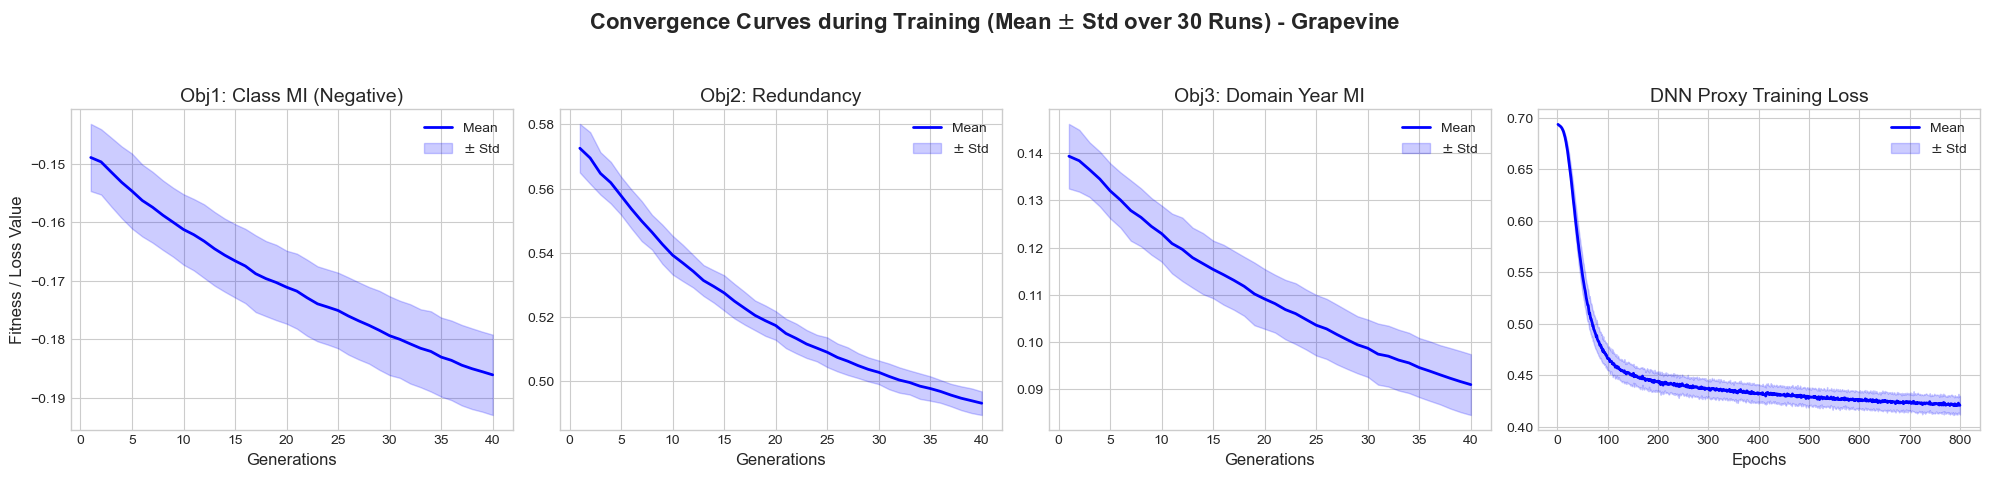

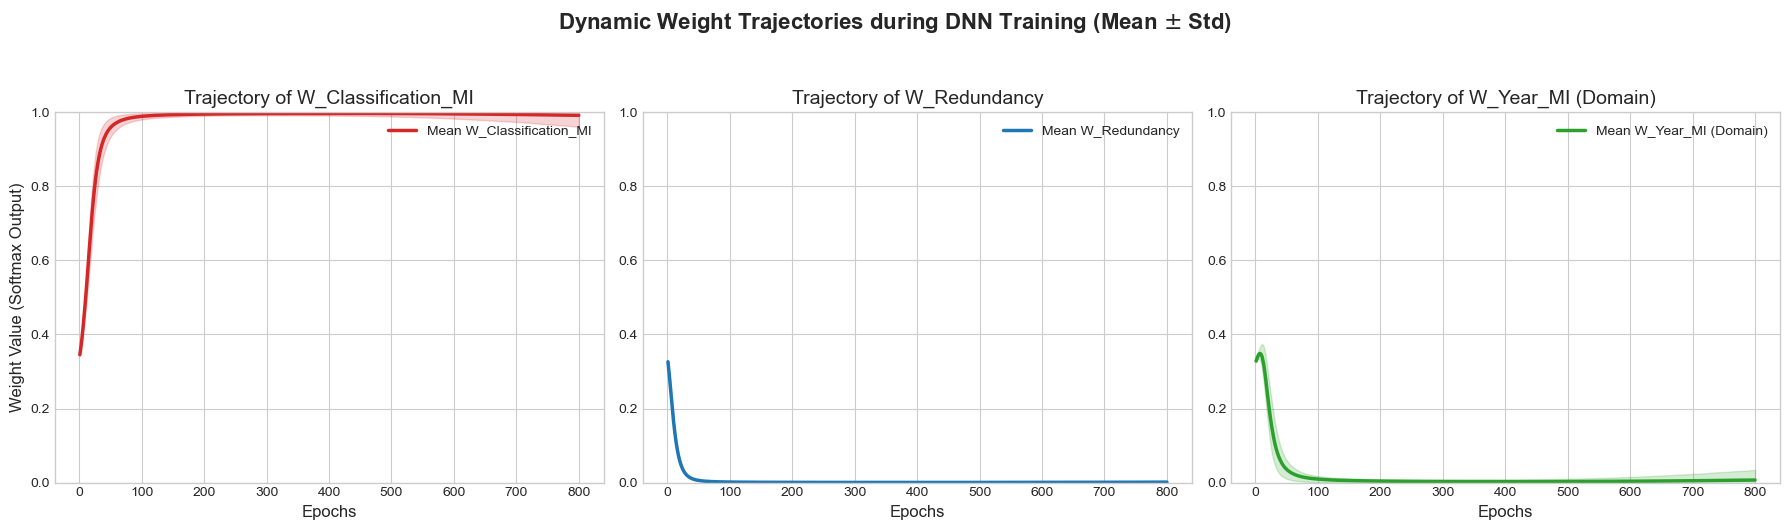

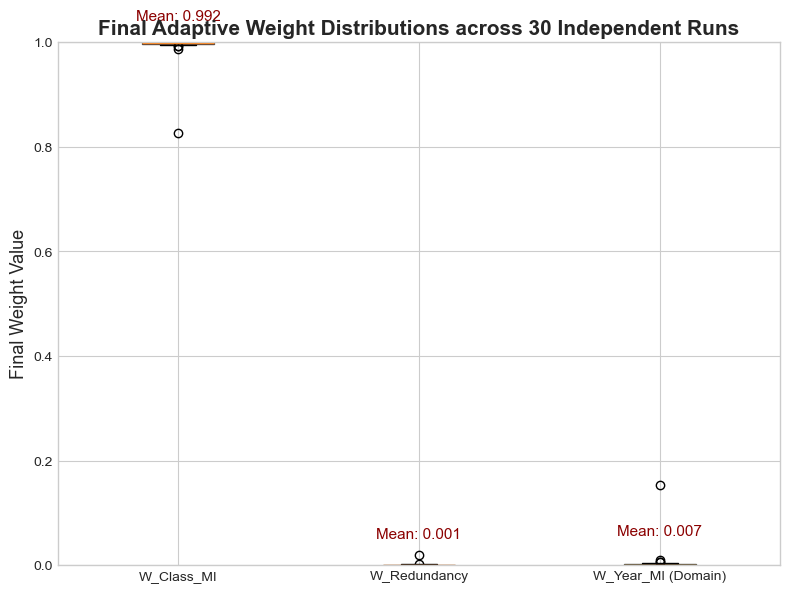

In [1]:
# ==============================================================
# 专属验证实验：Grapevine Diseases (Random Split vs. Temporal Transfer)
# 包含：GA-NN (Adaptive) 30次运行 + 自动绘制收敛曲线与权重分布箱线图
# 运行环境：Jupyter Notebook 兼容版
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import time
import torch
import matplotlib.pyplot as plt

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Ours ---
# Ensure these imports match your project structure
from utils.data_loader import load_grapevine_data
from core.ga_utils import jfs, keep_elite
from core.fitness_fast import Obj_Max_MI_Fast, Obj2_Min_Redundancy_Safe, Obj3_Min_Year_MI_Fast
from core.networks import train_softmask_dnn_proxy

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def calc_mean_std(x): 
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def get_top_k(scores, k):
    idx = np.argsort(scores)[::-1][:k]
    return idx if len(idx) > 0 else np.array([0])

# ==============================================================
# 1. Core Evaluation Routine (OURS ONLY)
# ==============================================================
def run_ours_only(xtrain, xtest, ytrain, ytest, yyear_tr, run_idx, exp_name):
    print(f"\n  [{exp_name} - Run {run_idx}] Pre-computing Mutual Information...")
    mi_class = mutual_info_classif(xtrain, ytrain, random_state=42)
    mi_year = mutual_info_classif(xtrain, yyear_tr, random_state=42)
    
    # --- 严格对齐 SOTA 算法的基准参数 ---
    opts = {
        'xt_in': xtrain, 
        'mi_class': mi_class, 
        'mi_year': mi_year, 
        'N': 91, 
        'T': 40, 
        'CR': 0.8, 
        'MR': 0.01
    }
    
    results = []
    clf = LinearDiscriminantAnalysis()
    
    print(f"    -> Optimizing with GA-NN (Adaptive)...")
    
    start_time = time.time()
    
    # 1. 独立单目标 GA 搜索 (记录收敛曲线 curve)
    res1 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_class'))
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe)
    res3 = jfs(opts, Obj3_Min_Year_MI_Fast)
    
    curve1 = res1.get('curve', [])
    curve2 = res2.get('curve', [])
    curve3 = res3.get('curve', [])
    
    # 2. 提取精英解
    pop1 = keep_elite(**res1)
    pop2 = keep_elite(**res2)
    pop3 = keep_elite(**res3)
    
    # 3. 深度特征融合 (记录最终的动态权重 lam, w_hist 和 Loss 历史 l_hist)
    sc_ad, lam, w_hist, l_hist = train_softmask_dnn_proxy(
        pop1, pop2, pop3, xtrain, ytrain, xtrain.shape[1], True, temp_scale=5.0
    )
    
    elapsed_time = time.time() - start_time
    
    # 验证分类精度 (K=1..15)
    for k in range(1, 16):
        idx = get_top_k(sc_ad, k)
        acc = clf.fit(xtrain[:, idx], ytrain).score(xtest[:, idx], ytest)
        
        results.append({
            "Experiment": exp_name, 
            "Run": run_idx, 
            "Method": "GA-NN (Adaptive)", 
            "K": k, 
            "Accuracy": acc, 
            "Time_Seconds": elapsed_time
        })
            
    # 打包返回结果和绘图所需的数据
    return results, (curve1, curve2, curve3, l_hist, lam, w_hist)

# ==============================================================
# 2. Orchestrator & Execution
# ==============================================================
def run_benchmark(features, class_labels, year_raw, target_year_val=4, n_runs=30):
    le_year = LabelEncoder()
    y_year_encoded = le_year.fit_transform(year_raw)
    target_year_idx = le_year.transform([target_year_val])[0] if target_year_val in year_raw else np.max(y_year_encoded)

    all_results = []
    
    # 绘图数据存储器
    all_c1, all_c2, all_c3 = [], [], []
    all_loss, all_weights, all_w_hist = [], [], []

    print("="*80)
    print(f"Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Grapevine): {n_runs} Runs")
    print("="*80)
    
    global_start_time = time.time()
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # --- Exp 1: Random Split ---
        xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, _ = train_test_split(
            features, class_labels, y_year_encoded, 
            test_size=0.3, stratify=class_labels, random_state=current_seed
        )
        
        res1, histories1 = run_ours_only(xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, run_idx, "Exp1_Random_Split")
        all_results.extend(res1)
        
        # 收集绘图数据 (仅以 Random Split 为代表，避免 60 次混合统计干扰曲线分布)
        c1, c2, c3, l_hist, lam, w_hist = histories1
        all_c1.append(c1)
        all_c2.append(c2)
        all_c3.append(c3)
        all_loss.append(l_hist)
        all_weights.append(lam)
        all_w_hist.append(w_hist)
        
        # --- Exp 2: Temporal Transfer ---
        test_mask = (y_year_encoded == target_year_idx)
        train_mask = ~test_mask
        
        xt_tr2, xt_te2 = features[train_mask], features[test_mask]
        yt_tr2, yt_te2 = class_labels[train_mask], class_labels[test_mask]
        yr_tr2 = y_year_encoded[train_mask]
        
        res2, _ = run_ours_only(xt_tr2, xt_te2, yt_tr2, yt_te2, yr_tr2, run_idx, "Exp2_Temporal_Transfer")
        all_results.extend(res2)

    # ==============================================================
    # 3. Output Generation (Tables)
    # ==============================================================
    df = pd.DataFrame(all_results)

    print("\n\n" + "="*80)
    print("             FINAL OURS-ONLY OUTPUT TABLES (Mean ± Std)")
    print("="*80)
    
    tb1 = df[df["Experiment"] == "Exp1_Random_Split"].pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    print("\n[TABLE 1] Exp 1 (Random Split) - Classification Accuracy")
    print(tb1)
    tb1.to_csv("Final_Grapevine_Exp1_Ours.csv") 
    
    tb2 = df[df["Experiment"] == "Exp2_Temporal_Transfer"].pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    print("\n[TABLE 2] Exp 2 (Temporal Transfer) - Classification Accuracy")
    print(tb2)
    tb2.to_csv("Final_Grapevine_Exp2_Ours.csv")

    tb_time = df.pivot_table(index="Method", values="Time_Seconds", aggfunc=calc_mean_std)
    print("\n[TABLE 3] Execution Time (Seconds)")
    print(tb_time)
    tb_time.to_csv("Final_Grapevine_Time_Ours.csv")

    total_minutes = (time.time() - global_start_time) / 60
    print(f"\n-> GA-NN 30 次运行完毕！共耗时 {total_minutes:.2f} 分钟。开始绘制审稿人要求的图表...\n")

    # ==============================================================
    # 4. Plotting for Reviewers (收敛曲线与权重分布)
    # ==============================================================
    plot_reviewer_figures(all_c1, all_c2, all_c3, all_loss, all_weights, all_w_hist)


def plot_reviewer_figures(c1_list, c2_list, c3_list, loss_list, weights_list, w_hist_list):
    """专门为审稿人生成论文级别的图表 (Grapevine Dataset 专属)"""
    
    c1_arr = np.array(c1_list)
    c2_arr = np.array(c2_list)
    c3_arr = np.array(c3_list)
    loss_arr = np.array(loss_list)
    weights_arr = np.array(weights_list)         # shape: (30, 3)
    w_hist_arr = np.array(w_hist_list)           # shape: (30, epochs, 3)

    plt.style.use('seaborn-v0_8-whitegrid')
    
    # ---------------------------------------------------------
    # 图 1: 收敛曲线 (GA 3个目标 + DNN Loss)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    fig.suptitle('Convergence Curves during Training (Mean $\pm$ Std over 30 Runs) - Grapevine', fontsize=16, fontweight='bold', y=1.05)

    titles = ['Obj1: Class MI (Negative)', 'Obj2: Redundancy', 'Obj3: Domain Year MI', 'DNN Proxy Training Loss']
    data_arrays = [c1_arr, c2_arr, c3_arr, loss_arr]
    x_labels = ['Generations'] * 3 + ['Epochs']

    for i in range(4):
        ax = axes[i]
        mean_val = np.mean(data_arrays[i], axis=0)
        std_val = np.std(data_arrays[i], axis=0)
        x_axis = np.arange(1, len(mean_val) + 1)
        
        ax.plot(x_axis, mean_val, color='b', linewidth=2, label='Mean')
        ax.fill_between(x_axis, mean_val - std_val, mean_val + std_val, color='b', alpha=0.2, label='$\pm$ Std')
        
        ax.set_title(titles[i], fontsize=14)
        ax.set_xlabel(x_labels[i], fontsize=12)
        if i == 0: ax.set_ylabel('Fitness / Loss Value', fontsize=12)
        ax.legend()

    plt.tight_layout()
    plt.savefig("Grapevine_Fig1_Convergence.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 2: 动态权重变化轨迹 (3个子图，展示 w1, w2, w3 的 Epoch 变化)
    # ---------------------------------------------------------
    fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
    fig2.suptitle('Dynamic Weight Trajectories during DNN Training (Mean $\pm$ Std)', fontsize=16, fontweight='bold', y=1.05)

    weight_names = ['W_Classification_MI', 'W_Redundancy', 'W_Year_MI (Domain)']
    line_colors = ['#d62728', '#1f77b4', '#2ca02c'] # 红, 蓝, 绿

    for i in range(3):
        ax = axes2[i]
        mean_w = np.mean(w_hist_arr[:, :, i], axis=0)
        std_w = np.std(w_hist_arr[:, :, i], axis=0)
        epochs_x = np.arange(1, len(mean_w) + 1)

        ax.plot(epochs_x, mean_w, color=line_colors[i], linewidth=2.5, label=f'Mean {weight_names[i]}')
        ax.fill_between(epochs_x, mean_w - std_w, mean_w + std_w, color=line_colors[i], alpha=0.2)

        ax.set_title(f'Trajectory of {weight_names[i]}', fontsize=14)
        ax.set_xlabel('Epochs', fontsize=12)
        if i == 0: ax.set_ylabel('Weight Value (Softmax Output)', fontsize=12)
        ax.set_ylim(0, 1.0)
        ax.legend()

    plt.tight_layout()
    plt.savefig("Grapevine_Fig2_Weight_Trajectories.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 3: 最终自适应权重分布 (Boxplot)
    # ---------------------------------------------------------
    plt.figure(figsize=(8, 6))
    
    # 使用箱线图展示 30 次运行的权重分布
    box = plt.boxplot([weights_arr[:, 0], weights_arr[:, 1], weights_arr[:, 2]], 
                      labels=['W_Class_MI', 'W_Redundancy', 'W_Year_MI (Domain)'],
                      patch_artist=True)
    
    colors = ['#FF9999', '#66B2FF', '#99FF99']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
        
    plt.title('Final Adaptive Weight Distributions across 30 Independent Runs', fontsize=15, fontweight='bold')
    plt.ylabel('Final Weight Value', fontsize=13)
    plt.ylim(0, 1.0)
    
    # 标注出均值
    means = np.mean(weights_arr, axis=0)
    for i, mean_val in enumerate(means):
        plt.text(i+1, mean_val + 0.05, f'Mean: {mean_val:.3f}', horizontalalignment='center', fontsize=11, color='darkred')

    plt.tight_layout()
    plt.savefig("Grapevine_Fig3_Weight_Boxplot.pdf", bbox_inches='tight', dpi=300)
    plt.show()

if __name__ == "__main__":
    class Args:
        n_run = 30         # 独立运行次数
        target_year = 4    # LOYO 验证的目标年份
        K = 15             # 评估的最大特征数
        
    args = Args()

    try:
        print("Loading Data...")
        X, y_cls, y_year_raw = load_grapevine_data()
        run_benchmark(X, y_cls, y_year_raw, target_year_val=args.target_year, n_runs=args.n_run)
    except Exception as e:
        print(f"Error: {e}")

Loading Data...
Loading Grapevine Dataset...
Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Grapevine): 30 Runs

  [Exp1_Random_Split - Run 1] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 1] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp1_Random_Split - Run 2] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 2] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp1_Random_Split - Run 3] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 3] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp1_Random_Split - Run 4] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 4] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Ada

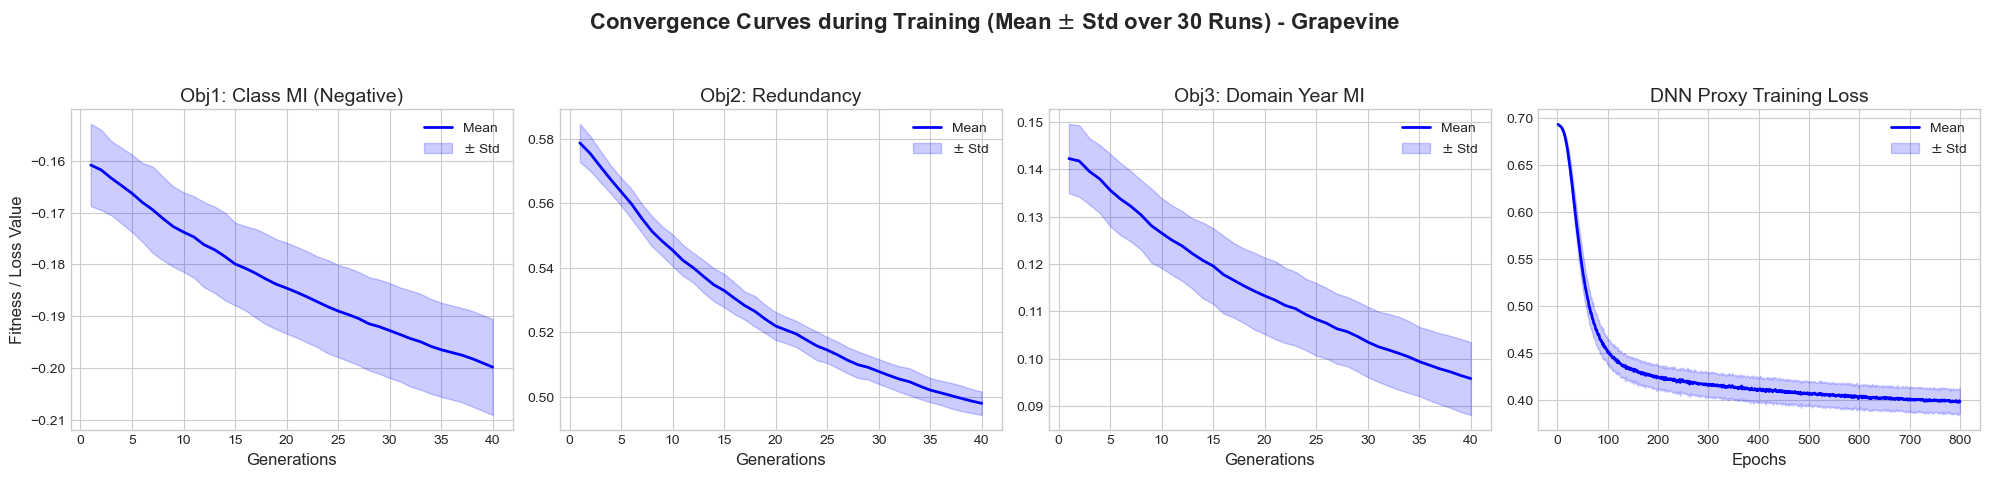

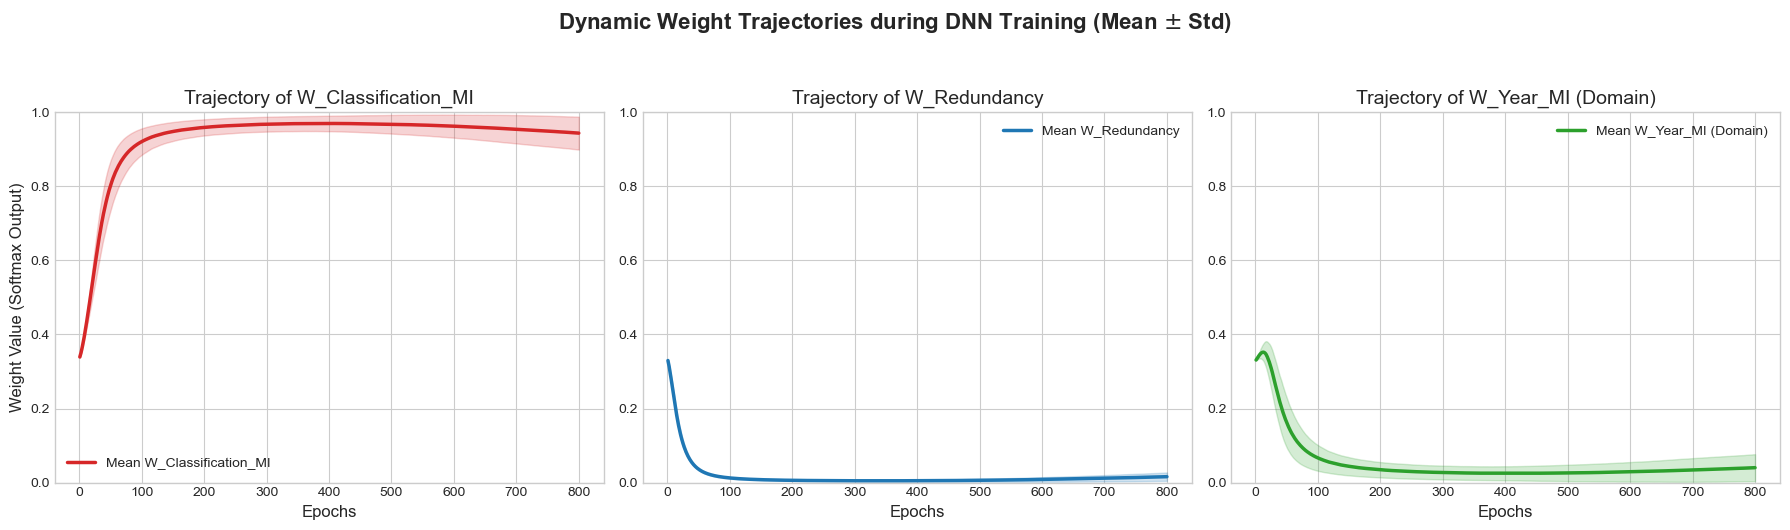

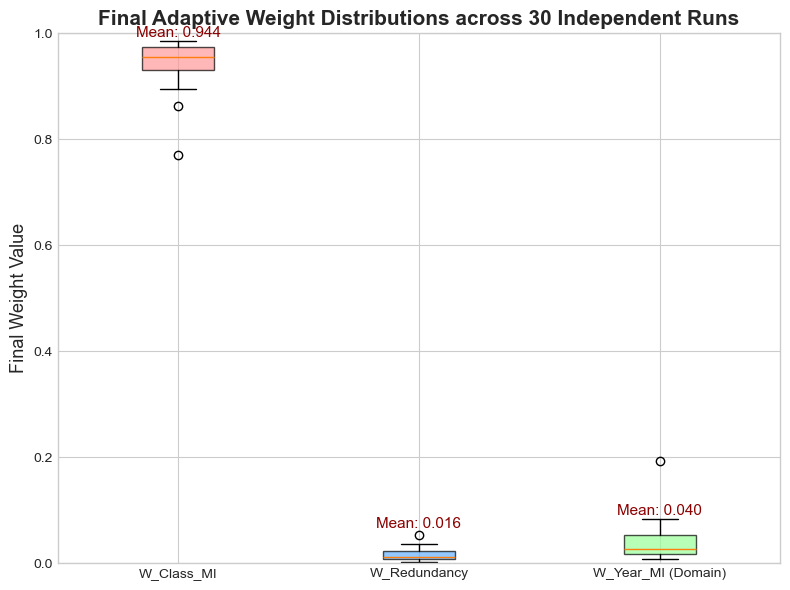

In [3]:
# ==============================================================
# 专属验证实验：Grapevine Diseases (Random Split vs. Temporal Transfer)
# 包含：GA-NN (Adaptive) 30次运行 + 自动绘制收敛曲线与权重分布箱线图
# 运行环境：Jupyter Notebook 兼容版
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import time
import torch
import matplotlib.pyplot as plt

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Ours ---
# Ensure these imports match your project structure
from utils.data_loader import load_grapevine_data
from core.ga_utils import jfs, keep_elite
from core.fitness_fast import Obj_Max_MI_Fast, Obj2_Min_Redundancy_Safe, Obj3_Min_Year_MI_Fast
from core.networks import train_softmask_dnn_proxy

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def calc_mean_std(x): 
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def get_top_k(scores, k):
    idx = np.argsort(scores)[::-1][:k]
    return idx if len(idx) > 0 else np.array([0])

# ==============================================================
# 1. Core Evaluation Routine (OURS ONLY)
# ==============================================================
def run_ours_only(xtrain, xtest, ytrain, ytest, yyear_tr, run_idx, exp_name):
    print(f"\n  [{exp_name} - Run {run_idx}] Pre-computing Mutual Information...")
    mi_class = mutual_info_classif(xtrain, ytrain, random_state=42)
    mi_year = mutual_info_classif(xtrain, yyear_tr, random_state=42)
    
    # --- 严格对齐 SOTA 算法的基准参数 ---
    opts = {
        'xt_in': xtrain, 
        'mi_class': mi_class, 
        'mi_year': mi_year, 
        'N': 91, 
        'T': 40, 
        'CR': 0.8, 
        'MR': 0.01
    }
    
    results = []
    clf = LinearDiscriminantAnalysis()
    
    print(f"    -> Optimizing with GA-NN (Adaptive)...")
    
    start_time = time.time()
    
    # 1. 独立单目标 GA 搜索 (记录收敛曲线 curve)
    res1 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_class'))
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe)
    res3 = jfs(opts, Obj3_Min_Year_MI_Fast)
    
    curve1 = res1.get('curve', [])
    curve2 = res2.get('curve', [])
    curve3 = res3.get('curve', [])
    
    # 2. 提取精英解
    pop1 = keep_elite(**res1)
    pop2 = keep_elite(**res2)
    pop3 = keep_elite(**res3)
    
    # 3. 深度特征融合 (记录最终的动态权重 lam, w_hist 和 Loss 历史 l_hist)
    sc_ad, lam, w_hist, l_hist = train_softmask_dnn_proxy(
        pop1, pop2, pop3, xtrain, ytrain, xtrain.shape[1], True, temp_scale=10.0
    )
    
    elapsed_time = time.time() - start_time
    
    # 验证分类精度 (K=1..15)
    for k in range(1, 16):
        idx = get_top_k(sc_ad, k)
        acc = clf.fit(xtrain[:, idx], ytrain).score(xtest[:, idx], ytest)
        
        results.append({
            "Experiment": exp_name, 
            "Run": run_idx, 
            "Method": "GA-NN (Adaptive)", 
            "K": k, 
            "Accuracy": acc, 
            "Time_Seconds": elapsed_time
        })
            
    # 打包返回结果和绘图所需的数据
    return results, (curve1, curve2, curve3, l_hist, lam, w_hist)

# ==============================================================
# 2. Orchestrator & Execution
# ==============================================================
def run_benchmark(features, class_labels, year_raw, target_year_val=4, n_runs=30):
    le_year = LabelEncoder()
    y_year_encoded = le_year.fit_transform(year_raw)
    target_year_idx = le_year.transform([target_year_val])[0] if target_year_val in year_raw else np.max(y_year_encoded)

    all_results = []
    
    # 绘图数据存储器
    all_c1, all_c2, all_c3 = [], [], []
    all_loss, all_weights, all_w_hist = [], [], []

    print("="*80)
    print(f"Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Grapevine): {n_runs} Runs")
    print("="*80)
    
    global_start_time = time.time()
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # --- Exp 1: Random Split ---
        xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, _ = train_test_split(
            features, class_labels, y_year_encoded, 
            test_size=0.3, stratify=class_labels, random_state=current_seed
        )
        
        res1, histories1 = run_ours_only(xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, run_idx, "Exp1_Random_Split")
        all_results.extend(res1)
        
        # 收集绘图数据 (仅以 Random Split 为代表，避免 60 次混合统计干扰曲线分布)
        c1, c2, c3, l_hist, lam, w_hist = histories1
        all_c1.append(c1)
        all_c2.append(c2)
        all_c3.append(c3)
        all_loss.append(l_hist)
        all_weights.append(lam)
        all_w_hist.append(w_hist)
        
        # --- Exp 2: Temporal Transfer ---
        test_mask = (y_year_encoded == target_year_idx)
        train_mask = ~test_mask
        
        xt_tr2, xt_te2 = features[train_mask], features[test_mask]
        yt_tr2, yt_te2 = class_labels[train_mask], class_labels[test_mask]
        yr_tr2 = y_year_encoded[train_mask]
        
        res2, _ = run_ours_only(xt_tr2, xt_te2, yt_tr2, yt_te2, yr_tr2, run_idx, "Exp2_Temporal_Transfer")
        all_results.extend(res2)

    # ==============================================================
    # 3. Output Generation (Tables)
    # ==============================================================
    df = pd.DataFrame(all_results)

    print("\n\n" + "="*80)
    print("             FINAL OURS-ONLY OUTPUT TABLES (Mean ± Std)")
    print("="*80)
    
    tb1 = df[df["Experiment"] == "Exp1_Random_Split"].pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    print("\n[TABLE 1] Exp 1 (Random Split) - Classification Accuracy")
    print(tb1)
    tb1.to_csv("Final_Grapevine_Exp1_Ours.csv") 
    
    tb2 = df[df["Experiment"] == "Exp2_Temporal_Transfer"].pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    print("\n[TABLE 2] Exp 2 (Temporal Transfer) - Classification Accuracy")
    print(tb2)
    tb2.to_csv("Final_Grapevine_Exp2_Ours.csv")

    tb_time = df.pivot_table(index="Method", values="Time_Seconds", aggfunc=calc_mean_std)
    print("\n[TABLE 3] Execution Time (Seconds)")
    print(tb_time)
    tb_time.to_csv("Final_Grapevine_Time_Ours.csv")

    total_minutes = (time.time() - global_start_time) / 60
    print(f"\n-> GA-NN 30 次运行完毕！共耗时 {total_minutes:.2f} 分钟。开始绘制审稿人要求的图表...\n")

    # ==============================================================
    # 4. Plotting for Reviewers (收敛曲线与权重分布)
    # ==============================================================
    plot_reviewer_figures(all_c1, all_c2, all_c3, all_loss, all_weights, all_w_hist)


def plot_reviewer_figures(c1_list, c2_list, c3_list, loss_list, weights_list, w_hist_list):
    """专门为审稿人生成论文级别的图表 (Grapevine Dataset 专属)"""
    
    c1_arr = np.array(c1_list)
    c2_arr = np.array(c2_list)
    c3_arr = np.array(c3_list)
    loss_arr = np.array(loss_list)
    weights_arr = np.array(weights_list)         # shape: (30, 3)
    w_hist_arr = np.array(w_hist_list)           # shape: (30, epochs, 3)

    plt.style.use('seaborn-v0_8-whitegrid')
    
    # ---------------------------------------------------------
    # 图 1: 收敛曲线 (GA 3个目标 + DNN Loss)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    fig.suptitle('Convergence Curves during Training (Mean $\pm$ Std over 30 Runs) - Grapevine', fontsize=16, fontweight='bold', y=1.05)

    titles = ['Obj1: Class MI (Negative)', 'Obj2: Redundancy', 'Obj3: Domain Year MI', 'DNN Proxy Training Loss']
    data_arrays = [c1_arr, c2_arr, c3_arr, loss_arr]
    x_labels = ['Generations'] * 3 + ['Epochs']

    for i in range(4):
        ax = axes[i]
        mean_val = np.mean(data_arrays[i], axis=0)
        std_val = np.std(data_arrays[i], axis=0)
        x_axis = np.arange(1, len(mean_val) + 1)
        
        ax.plot(x_axis, mean_val, color='b', linewidth=2, label='Mean')
        ax.fill_between(x_axis, mean_val - std_val, mean_val + std_val, color='b', alpha=0.2, label='$\pm$ Std')
        
        ax.set_title(titles[i], fontsize=14)
        ax.set_xlabel(x_labels[i], fontsize=12)
        if i == 0: ax.set_ylabel('Fitness / Loss Value', fontsize=12)
        ax.legend()

    plt.tight_layout()
    plt.savefig("Grapevine_Fig1_Convergence.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 2: 动态权重变化轨迹 (3个子图，展示 w1, w2, w3 的 Epoch 变化)
    # ---------------------------------------------------------
    fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
    fig2.suptitle('Dynamic Weight Trajectories during DNN Training (Mean $\pm$ Std)', fontsize=16, fontweight='bold', y=1.05)

    weight_names = ['W_Classification_MI', 'W_Redundancy', 'W_Year_MI (Domain)']
    line_colors = ['#d62728', '#1f77b4', '#2ca02c'] # 红, 蓝, 绿

    for i in range(3):
        ax = axes2[i]
        mean_w = np.mean(w_hist_arr[:, :, i], axis=0)
        std_w = np.std(w_hist_arr[:, :, i], axis=0)
        epochs_x = np.arange(1, len(mean_w) + 1)

        ax.plot(epochs_x, mean_w, color=line_colors[i], linewidth=2.5, label=f'Mean {weight_names[i]}')
        ax.fill_between(epochs_x, mean_w - std_w, mean_w + std_w, color=line_colors[i], alpha=0.2)

        ax.set_title(f'Trajectory of {weight_names[i]}', fontsize=14)
        ax.set_xlabel('Epochs', fontsize=12)
        if i == 0: ax.set_ylabel('Weight Value (Softmax Output)', fontsize=12)
        ax.set_ylim(0, 1.0)
        ax.legend()

    plt.tight_layout()
    plt.savefig("Grapevine_Fig2_Weight_Trajectories.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 3: 最终自适应权重分布 (Boxplot)
    # ---------------------------------------------------------
    plt.figure(figsize=(8, 6))
    
    # 使用箱线图展示 30 次运行的权重分布
    box = plt.boxplot([weights_arr[:, 0], weights_arr[:, 1], weights_arr[:, 2]], 
                      labels=['W_Class_MI', 'W_Redundancy', 'W_Year_MI (Domain)'],
                      patch_artist=True)
    
    colors = ['#FF9999', '#66B2FF', '#99FF99']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
        
    plt.title('Final Adaptive Weight Distributions across 30 Independent Runs', fontsize=15, fontweight='bold')
    plt.ylabel('Final Weight Value', fontsize=13)
    plt.ylim(0, 1.0)
    
    # 标注出均值
    means = np.mean(weights_arr, axis=0)
    for i, mean_val in enumerate(means):
        plt.text(i+1, mean_val + 0.05, f'Mean: {mean_val:.3f}', horizontalalignment='center', fontsize=11, color='darkred')

    plt.tight_layout()
    plt.savefig("Grapevine_Fig3_Weight_Boxplot.pdf", bbox_inches='tight', dpi=300)
    plt.show()

if __name__ == "__main__":
    class Args:
        n_run = 30         # 独立运行次数
        target_year = 4    # LOYO 验证的目标年份
        K = 15             # 评估的最大特征数
        
    args = Args()

    try:
        print("Loading Data...")
        X, y_cls, y_year_raw = load_grapevine_data()
        run_benchmark(X, y_cls, y_year_raw, target_year_val=args.target_year, n_runs=args.n_run)
    except Exception as e:
        print(f"Error: {e}")

Loading Data...
Loading Grapevine Dataset...
Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Grapevine): 30 Runs

  [Exp1_Random_Split - Run 1] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 1] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp1_Random_Split - Run 2] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 2] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp1_Random_Split - Run 3] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 3] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp1_Random_Split - Run 4] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Adaptive)...

  [Exp2_Temporal_Transfer - Run 4] Pre-computing Mutual Information...
    -> Optimizing with GA-NN (Ada

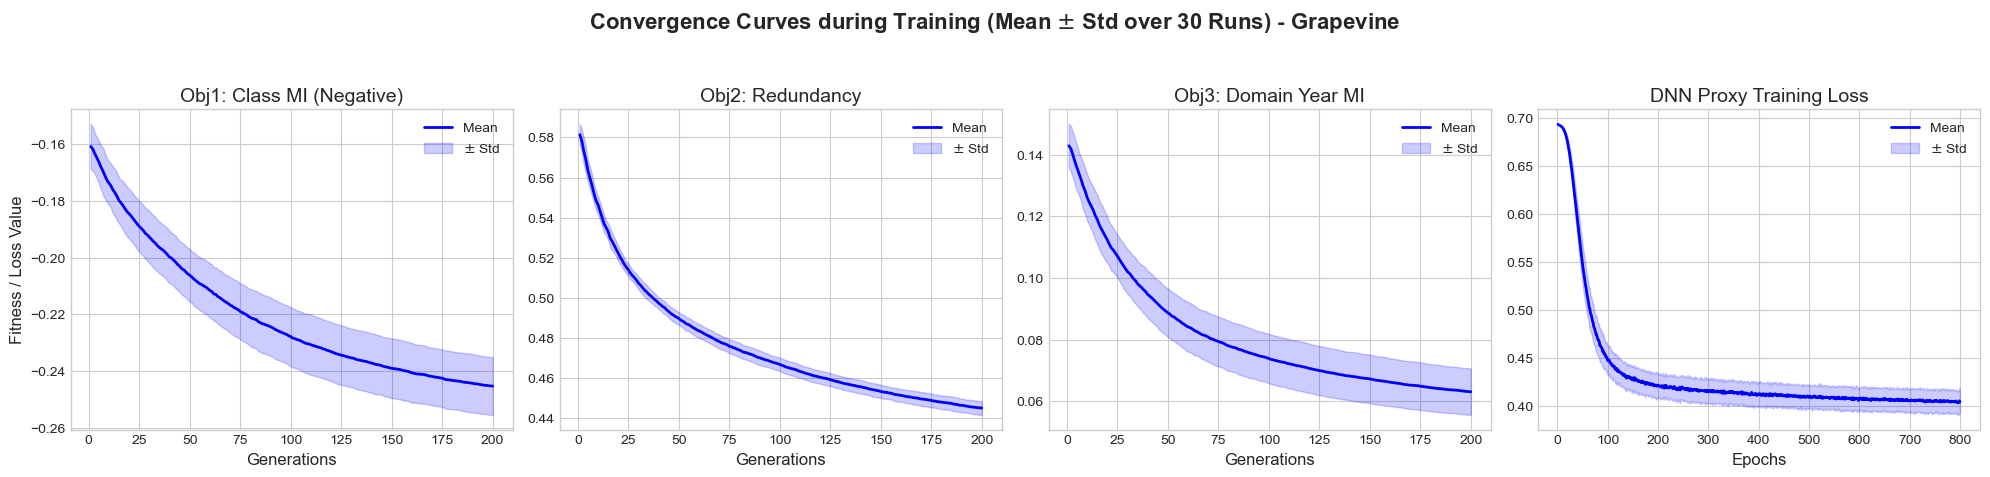

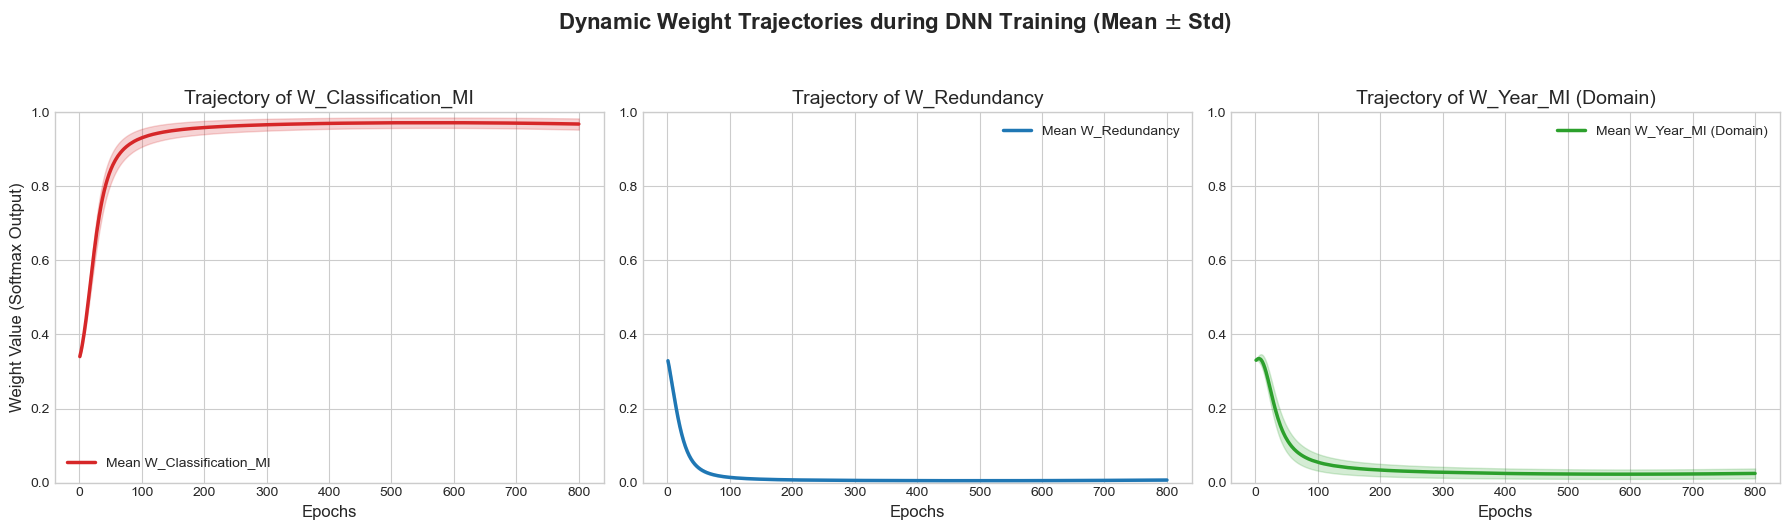

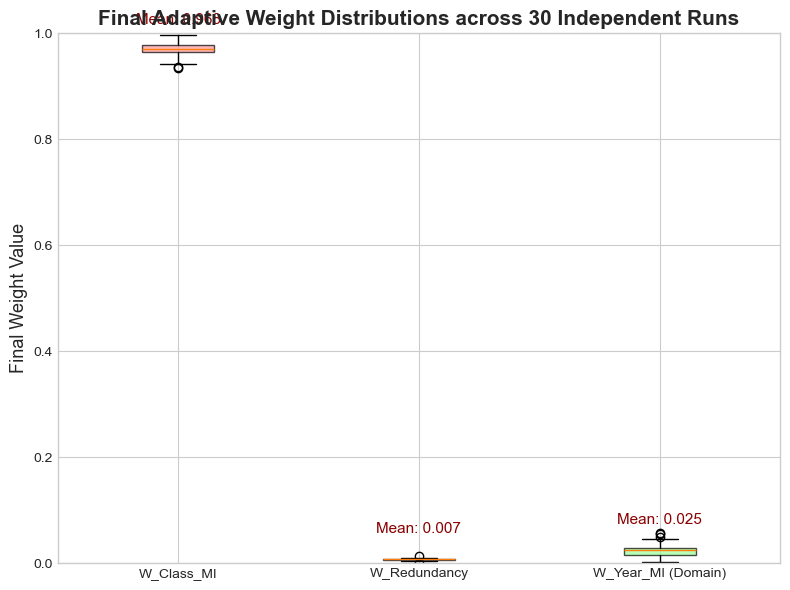

In [5]:
# ==============================================================
# 专属验证实验：Grapevine Diseases (Random Split vs. Temporal Transfer)
# 包含：GA-NN (Adaptive) 30次运行 + 自动绘制收敛曲线与权重分布箱线图
# 运行环境：Jupyter Notebook 兼容版
# ==============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import random
import time
import torch
import matplotlib.pyplot as plt

# --- Sklearn ---
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# --- Ours ---
# Ensure these imports match your project structure
from utils.data_loader import load_grapevine_data
from core.ga_utils import jfs, keep_elite
from core.fitness_fast import Obj_Max_MI_Fast, Obj2_Min_Redundancy_Safe, Obj3_Min_Year_MI_Fast
from core.networks import train_softmask_dnn_proxy

# ==============================================================
# 0. Configuration & Utilities
# ==============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def calc_mean_std(x): 
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f} ± 0.0000"

def get_top_k(scores, k):
    idx = np.argsort(scores)[::-1][:k]
    return idx if len(idx) > 0 else np.array([0])

# ==============================================================
# 1. Core Evaluation Routine (OURS ONLY)
# ==============================================================
def run_ours_only(xtrain, xtest, ytrain, ytest, yyear_tr, run_idx, exp_name):
    print(f"\n  [{exp_name} - Run {run_idx}] Pre-computing Mutual Information...")
    mi_class = mutual_info_classif(xtrain, ytrain, random_state=42)
    mi_year = mutual_info_classif(xtrain, yyear_tr, random_state=42)
    
    # --- 严格对齐 SOTA 算法的基准参数 ---
    opts = {
        'xt_in': xtrain, 
        'mi_class': mi_class, 
        'mi_year': mi_year, 
        'N': 91, 
        'T': 200, 
        'CR': 0.8, 
        'MR': 0.01
    }
    
    results = []
    clf = LinearDiscriminantAnalysis()
    
    print(f"    -> Optimizing with GA-NN (Adaptive)...")
    
    start_time = time.time()
    
    # 1. 独立单目标 GA 搜索 (记录收敛曲线 curve)
    res1 = jfs(opts, lambda x, o: Obj_Max_MI_Fast(x, o, 'mi_class'))
    res2 = jfs(opts, Obj2_Min_Redundancy_Safe)
    res3 = jfs(opts, Obj3_Min_Year_MI_Fast)
    
    curve1 = res1.get('curve', [])
    curve2 = res2.get('curve', [])
    curve3 = res3.get('curve', [])
    
    # 2. 提取精英解
    pop1 = keep_elite(**res1)
    pop2 = keep_elite(**res2)
    pop3 = keep_elite(**res3)
    
    # 3. 深度特征融合 (记录最终的动态权重 lam, w_hist 和 Loss 历史 l_hist)
    sc_ad, lam, w_hist, l_hist = train_softmask_dnn_proxy(
        pop1, pop2, pop3, xtrain, ytrain, xtrain.shape[1], True, temp_scale=10.0
    )
    
    elapsed_time = time.time() - start_time
    
    # 验证分类精度 (K=1..15)
    for k in range(1, 16):
        idx = get_top_k(sc_ad, k)
        acc = clf.fit(xtrain[:, idx], ytrain).score(xtest[:, idx], ytest)
        
        results.append({
            "Experiment": exp_name, 
            "Run": run_idx, 
            "Method": "GA-NN (Adaptive)", 
            "K": k, 
            "Accuracy": acc, 
            "Time_Seconds": elapsed_time
        })
            
    # 打包返回结果和绘图所需的数据
    return results, (curve1, curve2, curve3, l_hist, lam, w_hist)

# ==============================================================
# 2. Orchestrator & Execution
# ==============================================================
def run_benchmark(features, class_labels, year_raw, target_year_val=4, n_runs=30):
    le_year = LabelEncoder()
    y_year_encoded = le_year.fit_transform(year_raw)
    target_year_idx = le_year.transform([target_year_val])[0] if target_year_val in year_raw else np.max(y_year_encoded)

    all_results = []
    
    # 绘图数据存储器
    all_c1, all_c2, all_c3 = [], [], []
    all_loss, all_weights, all_w_hist = [], [], []

    print("="*80)
    print(f"Starting EXCLUSIVE BENCHMARK FOR OUR METHOD (Grapevine): {n_runs} Runs")
    print("="*80)
    
    global_start_time = time.time()
    
    for run_idx in range(1, n_runs + 1):
        current_seed = 42 + run_idx
        set_seed(current_seed)
        
        # --- Exp 1: Random Split ---
        xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, _ = train_test_split(
            features, class_labels, y_year_encoded, 
            test_size=0.3, stratify=class_labels, random_state=current_seed
        )
        
        res1, histories1 = run_ours_only(xt_tr1, xt_te1, yt_tr1, yt_te1, yr_tr1, run_idx, "Exp1_Random_Split")
        all_results.extend(res1)
        
        # 收集绘图数据 (仅以 Random Split 为代表，避免 60 次混合统计干扰曲线分布)
        c1, c2, c3, l_hist, lam, w_hist = histories1
        all_c1.append(c1)
        all_c2.append(c2)
        all_c3.append(c3)
        all_loss.append(l_hist)
        all_weights.append(lam)
        all_w_hist.append(w_hist)
        
        # --- Exp 2: Temporal Transfer ---
        test_mask = (y_year_encoded == target_year_idx)
        train_mask = ~test_mask
        
        xt_tr2, xt_te2 = features[train_mask], features[test_mask]
        yt_tr2, yt_te2 = class_labels[train_mask], class_labels[test_mask]
        yr_tr2 = y_year_encoded[train_mask]
        
        res2, _ = run_ours_only(xt_tr2, xt_te2, yt_tr2, yt_te2, yr_tr2, run_idx, "Exp2_Temporal_Transfer")
        all_results.extend(res2)

    # ==============================================================
    # 3. Output Generation (Tables)
    # ==============================================================
    df = pd.DataFrame(all_results)

    print("\n\n" + "="*80)
    print("             FINAL OURS-ONLY OUTPUT TABLES (Mean ± Std)")
    print("="*80)
    
    tb1 = df[df["Experiment"] == "Exp1_Random_Split"].pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    print("\n[TABLE 1] Exp 1 (Random Split) - Classification Accuracy")
    print(tb1)
    tb1.to_csv("Final_Grapevine_Exp1_Ours.csv") 
    
    tb2 = df[df["Experiment"] == "Exp2_Temporal_Transfer"].pivot_table(index="K", columns="Method", values="Accuracy", aggfunc=calc_mean_std)
    print("\n[TABLE 2] Exp 2 (Temporal Transfer) - Classification Accuracy")
    print(tb2)
    tb2.to_csv("Final_Grapevine_Exp2_Ours.csv")

    tb_time = df.pivot_table(index="Method", values="Time_Seconds", aggfunc=calc_mean_std)
    print("\n[TABLE 3] Execution Time (Seconds)")
    print(tb_time)
    tb_time.to_csv("Final_Grapevine_Time_Ours.csv")

    total_minutes = (time.time() - global_start_time) / 60
    print(f"\n-> GA-NN 30 次运行完毕！共耗时 {total_minutes:.2f} 分钟。开始绘制审稿人要求的图表...\n")

    # ==============================================================
    # 4. Plotting for Reviewers (收敛曲线与权重分布)
    # ==============================================================
    plot_reviewer_figures(all_c1, all_c2, all_c3, all_loss, all_weights, all_w_hist)


def plot_reviewer_figures(c1_list, c2_list, c3_list, loss_list, weights_list, w_hist_list):
    """专门为审稿人生成论文级别的图表 (Grapevine Dataset 专属)"""
    
    c1_arr = np.array(c1_list)
    c2_arr = np.array(c2_list)
    c3_arr = np.array(c3_list)
    loss_arr = np.array(loss_list)
    weights_arr = np.array(weights_list)         # shape: (30, 3)
    w_hist_arr = np.array(w_hist_list)           # shape: (30, epochs, 3)

    plt.style.use('seaborn-v0_8-whitegrid')
    
    # ---------------------------------------------------------
    # 图 1: 收敛曲线 (GA 3个目标 + DNN Loss)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    fig.suptitle('Convergence Curves during Training (Mean $\pm$ Std over 30 Runs) - Grapevine', fontsize=16, fontweight='bold', y=1.05)

    titles = ['Obj1: Class MI (Negative)', 'Obj2: Redundancy', 'Obj3: Domain Year MI', 'DNN Proxy Training Loss']
    data_arrays = [c1_arr, c2_arr, c3_arr, loss_arr]
    x_labels = ['Generations'] * 3 + ['Epochs']

    for i in range(4):
        ax = axes[i]
        mean_val = np.mean(data_arrays[i], axis=0)
        std_val = np.std(data_arrays[i], axis=0)
        x_axis = np.arange(1, len(mean_val) + 1)
        
        ax.plot(x_axis, mean_val, color='b', linewidth=2, label='Mean')
        ax.fill_between(x_axis, mean_val - std_val, mean_val + std_val, color='b', alpha=0.2, label='$\pm$ Std')
        
        ax.set_title(titles[i], fontsize=14)
        ax.set_xlabel(x_labels[i], fontsize=12)
        if i == 0: ax.set_ylabel('Fitness / Loss Value', fontsize=12)
        ax.legend()

    plt.tight_layout()
    plt.savefig("Grapevine_Fig1_Convergence.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 2: 动态权重变化轨迹 (3个子图，展示 w1, w2, w3 的 Epoch 变化)
    # ---------------------------------------------------------
    fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
    fig2.suptitle('Dynamic Weight Trajectories during DNN Training (Mean $\pm$ Std)', fontsize=16, fontweight='bold', y=1.05)

    weight_names = ['W_Classification_MI', 'W_Redundancy', 'W_Year_MI (Domain)']
    line_colors = ['#d62728', '#1f77b4', '#2ca02c'] # 红, 蓝, 绿

    for i in range(3):
        ax = axes2[i]
        mean_w = np.mean(w_hist_arr[:, :, i], axis=0)
        std_w = np.std(w_hist_arr[:, :, i], axis=0)
        epochs_x = np.arange(1, len(mean_w) + 1)

        ax.plot(epochs_x, mean_w, color=line_colors[i], linewidth=2.5, label=f'Mean {weight_names[i]}')
        ax.fill_between(epochs_x, mean_w - std_w, mean_w + std_w, color=line_colors[i], alpha=0.2)

        ax.set_title(f'Trajectory of {weight_names[i]}', fontsize=14)
        ax.set_xlabel('Epochs', fontsize=12)
        if i == 0: ax.set_ylabel('Weight Value (Softmax Output)', fontsize=12)
        ax.set_ylim(0, 1.0)
        ax.legend()

    plt.tight_layout()
    plt.savefig("Grapevine_Fig2_Weight_Trajectories.pdf", bbox_inches='tight', dpi=300)
    plt.show()

    # ---------------------------------------------------------
    # 图 3: 最终自适应权重分布 (Boxplot)
    # ---------------------------------------------------------
    plt.figure(figsize=(8, 6))
    
    # 使用箱线图展示 30 次运行的权重分布
    box = plt.boxplot([weights_arr[:, 0], weights_arr[:, 1], weights_arr[:, 2]], 
                      labels=['W_Class_MI', 'W_Redundancy', 'W_Year_MI (Domain)'],
                      patch_artist=True)
    
    colors = ['#FF9999', '#66B2FF', '#99FF99']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
        
    plt.title('Final Adaptive Weight Distributions across 30 Independent Runs', fontsize=15, fontweight='bold')
    plt.ylabel('Final Weight Value', fontsize=13)
    plt.ylim(0, 1.0)
    
    # 标注出均值
    means = np.mean(weights_arr, axis=0)
    for i, mean_val in enumerate(means):
        plt.text(i+1, mean_val + 0.05, f'Mean: {mean_val:.3f}', horizontalalignment='center', fontsize=11, color='darkred')

    plt.tight_layout()
    plt.savefig("Grapevine_Fig3_Weight_Boxplot.pdf", bbox_inches='tight', dpi=300)
    plt.show()

if __name__ == "__main__":
    class Args:
        n_run = 30         # 独立运行次数
        target_year = 4    # LOYO 验证的目标年份
        K = 15             # 评估的最大特征数
        
    args = Args()

    try:
        print("Loading Data...")
        X, y_cls, y_year_raw = load_grapevine_data()
        run_benchmark(X, y_cls, y_year_raw, target_year_val=args.target_year, n_runs=args.n_run)
    except Exception as e:
        print(f"Error: {e}")